# Which method to fix the v1 segmentations? Part 2: images

Visual comparison of the four segmentations of each NextBrain case (see
`methods_comparison_1_quantitative.ipynb` for the numbers):

- `v1`: `build_3d_segmentation.py` (nearest section), the starting point;
- `v1 + restore` (option 1): v1 followed by `restore.py`;
- `v2` (option 2): `build_3d_segmentation_v2.py`;
- `v2 + restore` (option 3): v2 followed by `restore.py`.

Contents:
1. Whole hemisphere, the four methods
2. Where each method changes v1
3. Zooms on the typical situations: block gaps, bridged sections, sulci, trimming, holes, small structures
4. The other four cases
5. Between two sections: one hidden section
6. What the images show

The first case is shown in detail, the others with fewer figures. All figures are also saved in
`outputs/methods_comparison/figures/`. The notebook reads the volumes but writes only figures. It
takes about 10 minutes to run.

In [1]:
import os, sys, glob
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle, Patch
from scipy import ndimage as ndi

%matplotlib inline
plt.rcParams["figure.dpi"] = 80

HERE = os.path.abspath(".")
OUT = os.path.join(HERE, "outputs", "methods_comparison")
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
T = os.path.join(OUT, "tables")
LUT_FILE = "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/lut/NextBrainLUT.txt"
sys.path.insert(0, HERE)
sys.path.insert(0, "/home/agustin/phd/synthseg_nextbrain/project/dev/wp2/fill_holes/manual")
import restore as R                                   # only for the label -> tissue class table

RES = 0.2
METHODS = ["v1", "v1_restore", "v2", "v2_restore"]
OUTLINE = {"v1": "w", "v1_restore": "deepskyblue", "v2": "orange", "v2_restore": "lime"}        # colours of the outlines on the MRI
OUTLINE_TXT = "v1 white, v1+restore blue, v2 orange, v2+restore green"
NAME = {"v1": "v1", "v1_restore": "v1 + restore", "v2": "v2", "v2_restore": "v2 + restore"}
FILES = {"v1": "v1/{c}_seg_0.2mm.nii.gz", "v1_restore": "v1_restore/{c}_seg_0.2mm_restored.nii.gz", "v2": "v2/{c}_seg_0.2mm_v2.nii.gz",
         "restore_steps": "v1_restore/{c}_seg_0.2mm_restored_steps.nii.gz", "v2_steps": "v2/{c}_seg_0.2mm_v2_steps.nii.gz",
         "v2_restore": "v2_restore/{c}_seg_0.2mm_v2_restored.nii.gz", "v2_restore_steps": "v2_restore/{c}_seg_0.2mm_v2_restored_steps.nii.gz"}
CASE_DIRS = {os.path.basename(os.path.dirname(d)): os.path.dirname(d)
             for d in sorted(glob.glob(os.path.join(HERE, "..", "NextBrain-Case-*", "*", "labels_blocks")))}
CASES = list(CASE_DIRS)
BG = (0.45, 0.45, 0.45)

def load_lut(path):
    names, rgb = {}, np.full((4096, 3), 0.5)
    for line in open(path):
        p = line.split()
        if len(p) >= 5 and p[0].isdigit():
            names[int(p[0])] = p[1]; rgb[int(p[0])] = [int(v) / 255 for v in p[2:5]]
    rgb[0] = BG
    return names, rgb
NAMES, RGB = load_lut(LUT_FILE)
L1 = R.load_l1_lut(4095); IS_CORTEX = np.isin(L1, R.CORTEX_L1); IS_CORTEX[0] = False

class Case:
    """The four segmentations of one case, the step maps and the MRI."""
    def __init__(self, case):
        self.case = case
        img = nib.load(os.path.join(OUT, FILES["v1"].format(c=case)))
        self.affine, self.shape = img.affine, img.shape
        self.vol = {k: np.asanyarray(nib.load(os.path.join(OUT, f.format(c=case))).dataobj) for k, f in FILES.items()}
        self.mri = nib.load(os.path.join(CASE_DIRS[case], "mri_rotated", "mri.nii.gz"))
        self._mri_data = None
        nz = [np.flatnonzero((self.vol["v1"] > 0).any(axis=tuple(a for a in range(3) if a != ax))) for ax in range(3)]
        self.lo = np.array([n[0] for n in nz]); self.hi = np.array([n[-1] + 1 for n in nz])

    def plane(self, key, axis, index, win=None):
        """2D slice of a volume; the first remaining axis is drawn horizontally. win = (slice, slice)."""
        a = np.take(self.vol[key], index, axis=axis)
        return a if win is None else a[win]

    def mri_plane(self, axis, index, win):
        """MRI resampled on the same plane and window (linear)."""
        if self._mri_data is None:
            self._mri_data = np.asanyarray(self.mri.dataobj).astype(np.float32)
        others = [a for a in range(3) if a != axis]
        u = np.arange(win[0].start, win[0].stop); v = np.arange(win[1].start, win[1].stop)
        ijk = np.zeros((len(u), len(v), 3)); ijk[..., axis] = index; ijk[..., others[0]] = u[:, None]; ijk[..., others[1]] = v[None, :]
        M = np.linalg.inv(self.mri.affine) @ self.affine
        return ndi.map_coordinates(self._mri_data, np.moveaxis(ijk @ M[:3, :3].T + M[:3, 3], -1, 0), order=1)

    def full_win(self, axis):
        o = [a for a in range(3) if a != axis]
        return (slice(int(self.lo[o[0]]), int(self.hi[o[0]])), slice(int(self.lo[o[1]]), int(self.hi[o[1]])))

AXNAME = {0: "sagittal", 1: "coronal", 2: "axial"}
def ext(win): return [win[0].start, win[0].stop, win[1].start, win[1].stop]
def show_lab(ax, a2d, win, title=None):
    ax.imshow(RGB[a2d.T], origin="lower", interpolation="nearest", extent=ext(win))
    if title: ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
def overlay(ax, mask2d, color, win, alpha=0.85):
    rgba = np.zeros(mask2d.T.shape + (4,)); rgba[mask2d.T] = (*to_rgb(color), alpha)
    ax.imshow(rgba, origin="lower", interpolation="nearest", extent=ext(win))

def best_slice(mask3d, axis):
    """Index along `axis` of the slice with most voxels of the mask."""
    return int(np.argmax(mask3d.sum(axis=tuple(a for a in range(3) if a != axis))))
def best_window(mask2d, size):
    """Window of size x size voxels with most voxels of the mask."""
    size = (min(size, mask2d.shape[0]), min(size, mask2d.shape[1]))
    d = ndi.uniform_filter(mask2d.astype(np.float32), size, mode="constant")
    c = np.unravel_index(np.argmax(d), d.shape)
    lo = [int(np.clip(c[a] - size[a] // 2, 0, mask2d.shape[a] - size[a])) for a in range(2)]
    return (slice(lo[0], lo[0] + size[0]), slice(lo[1], lo[1] + size[1]))

def zoom(C, axis, index, win, title, marks=None, save=None):
    """The four methods + MRI on the same window."""
    fig, axs = plt.subplots(1, 5, figsize=(23, 5.4))
    for ax, m in zip(axs, METHODS):
        show_lab(ax, C.plane(m, axis, index, win), win, NAME[m])
    mr = C.mri_plane(axis, index, win)
    axs[4].imshow(mr.T, origin="lower", cmap="gray", extent=ext(win), vmax=np.percentile(mr, 99.5))
    axs[4].set_title("MRI. Outline of the labels:\n" + OUTLINE_TXT, fontsize=8); axs[4].set_xticks([]); axs[4].set_yticks([])
    for m in METHODS:
        axs[4].contour((C.plane(m, axis, index, win) > 0).T, [0.5], colors=OUTLINE[m], linewidths=0.7, extent=ext(win))
    mm = (win[0].stop - win[0].start) * RES, (win[1].stop - win[1].start) * RES
    plt.suptitle(f"{C.case}, {AXNAME[axis]} slice {index}, window {mm[0]:.0f} x {mm[1]:.0f} mm. {title}", fontsize=11)
    plt.tight_layout()
    if save: fig.savefig(os.path.join(FIG, save), dpi=110)
    plt.show()
print("cases:", CASES)

cases: ['P57-16', 'P41-16', 'P58-16', 'P85-18', 'EX9-19']


## 1. Whole hemisphere, the four methods

One sagittal, one coronal and one axial slice through the middle of each hemisphere.
At this scale the four results look alike: the differences are thin (gaps, steps, borders).
The red boxes are drawn where the three candidates differ most from `v1` in that slice.

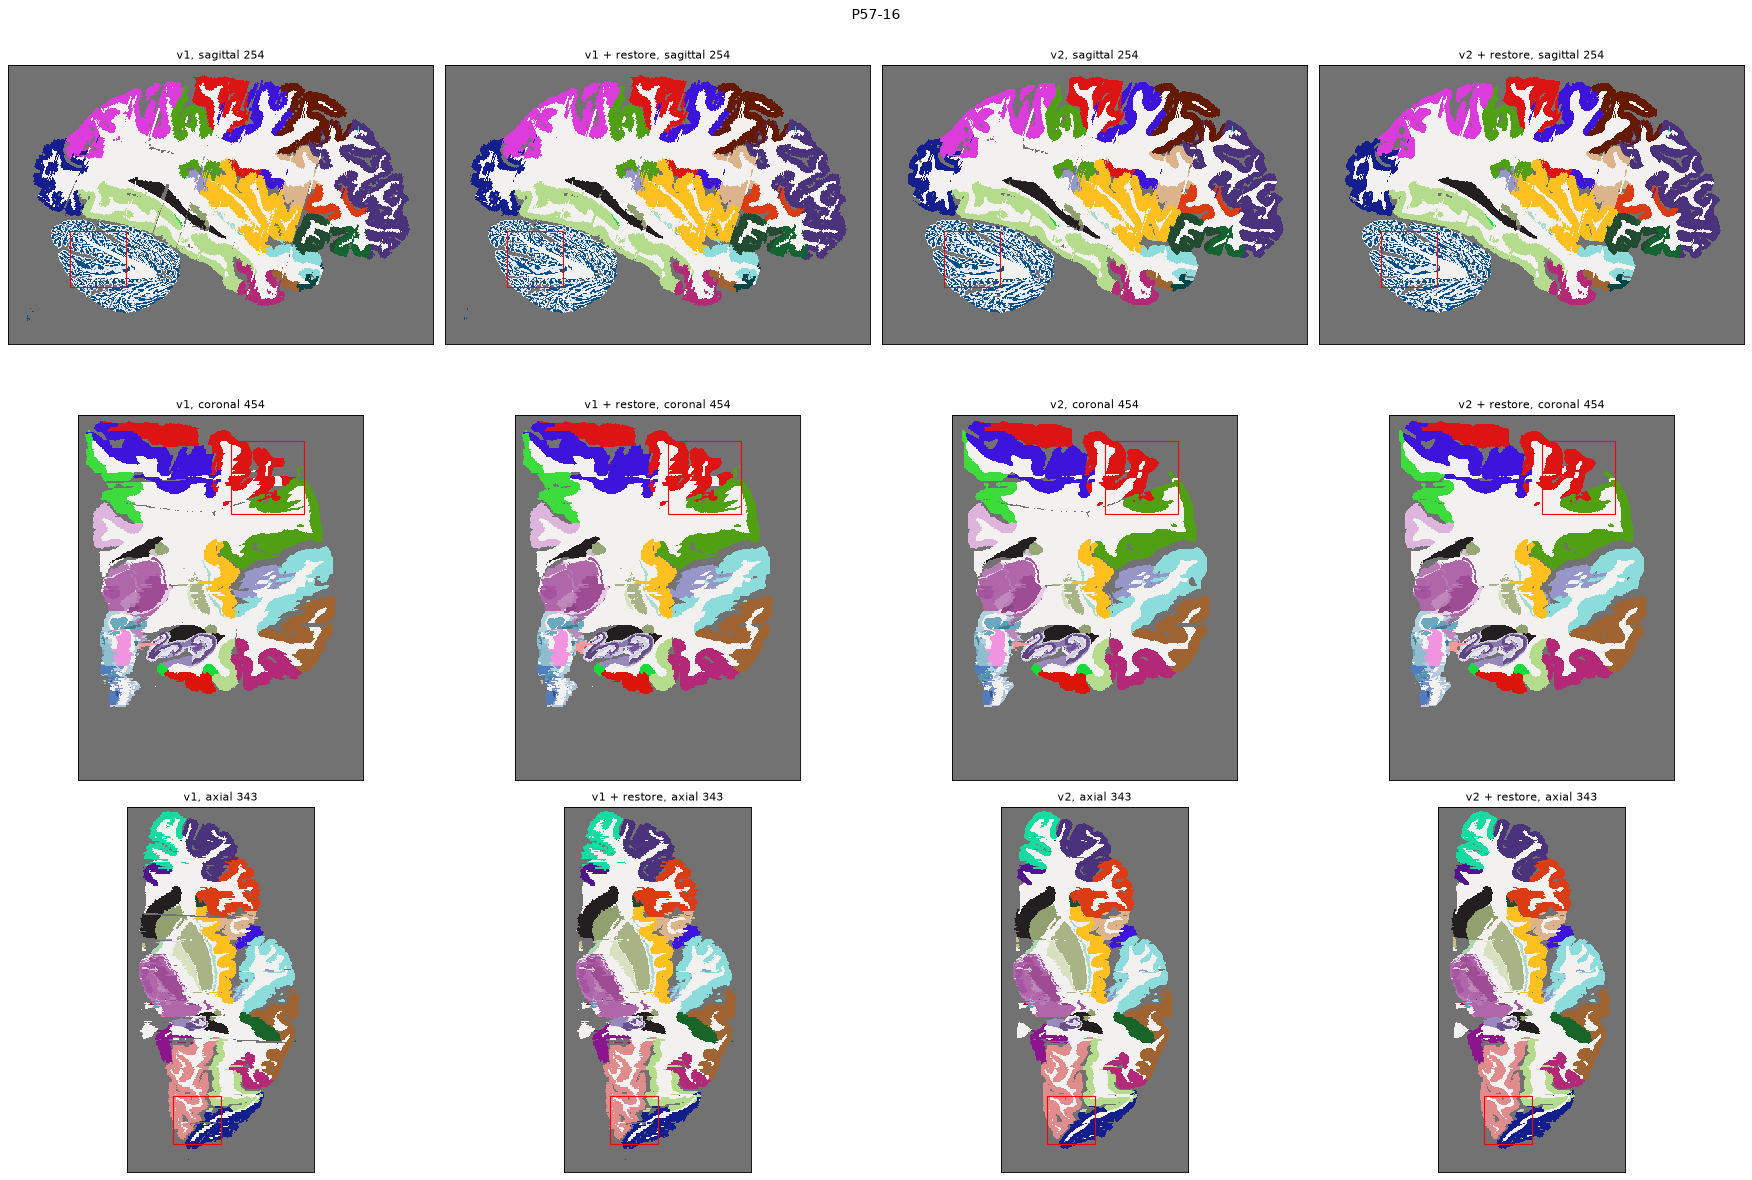

In [2]:
def overview(C, save=None):
    fig, axs = plt.subplots(3, 4, figsize=(22, 15))
    mid = ((C.lo + C.hi) // 2).astype(int)
    for row, axis in enumerate((0, 1, 2)):
        win = C.full_win(axis)
        changed = np.zeros(C.plane("v1", axis, mid[axis], win).shape, bool)
        for m in METHODS[1:]:
            changed |= C.plane(m, axis, mid[axis], win) != C.plane("v1", axis, mid[axis], win)
        bw = best_window(changed, 110)
        for ax, m in zip(axs[row], METHODS):
            show_lab(ax, C.plane(m, axis, mid[axis], win), win, f"{NAME[m]}, {AXNAME[axis]} {mid[axis]}")
            ax.add_patch(Rectangle((win[0].start + bw[0].start, win[1].start + bw[1].start), 110, 110, fill=False, ec="red", lw=1))
    plt.suptitle(C.case, fontsize=13); plt.tight_layout()
    if save: fig.savefig(os.path.join(FIG, save), dpi=90)
    plt.show()

C = Case(CASES[0])
overview(C, f"{C.case}_overview.png")

## 2. Where each method changes v1

Same sagittal slice, with the voxels that each method changed:
- **v1 + restore** (step map of `restore.py`): gap filled, crack filled, hole filled, block shifted;
- **v2** (step map of the script): bridged over missing sections / copied from the last usable
  section, trimmed with the MRI. Interpolated voxels (nearly all the volume) are not coloured;
  instead, the voxels whose label **differs from v1** are shown;
- **v2 + restore** (step map of `restore.py` run on v2): what `restore.py` still changes after v2.

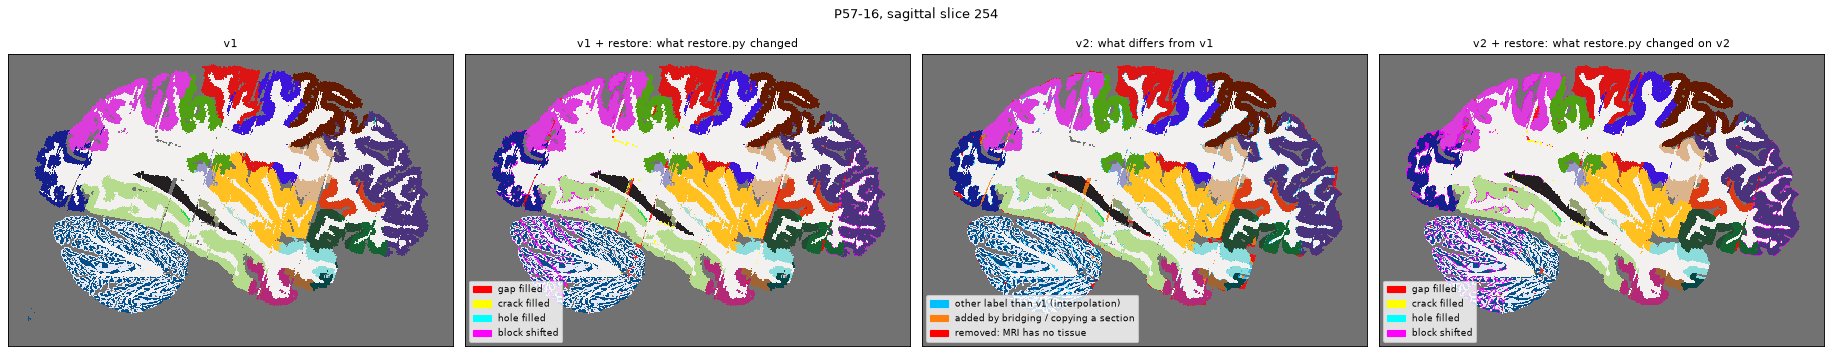

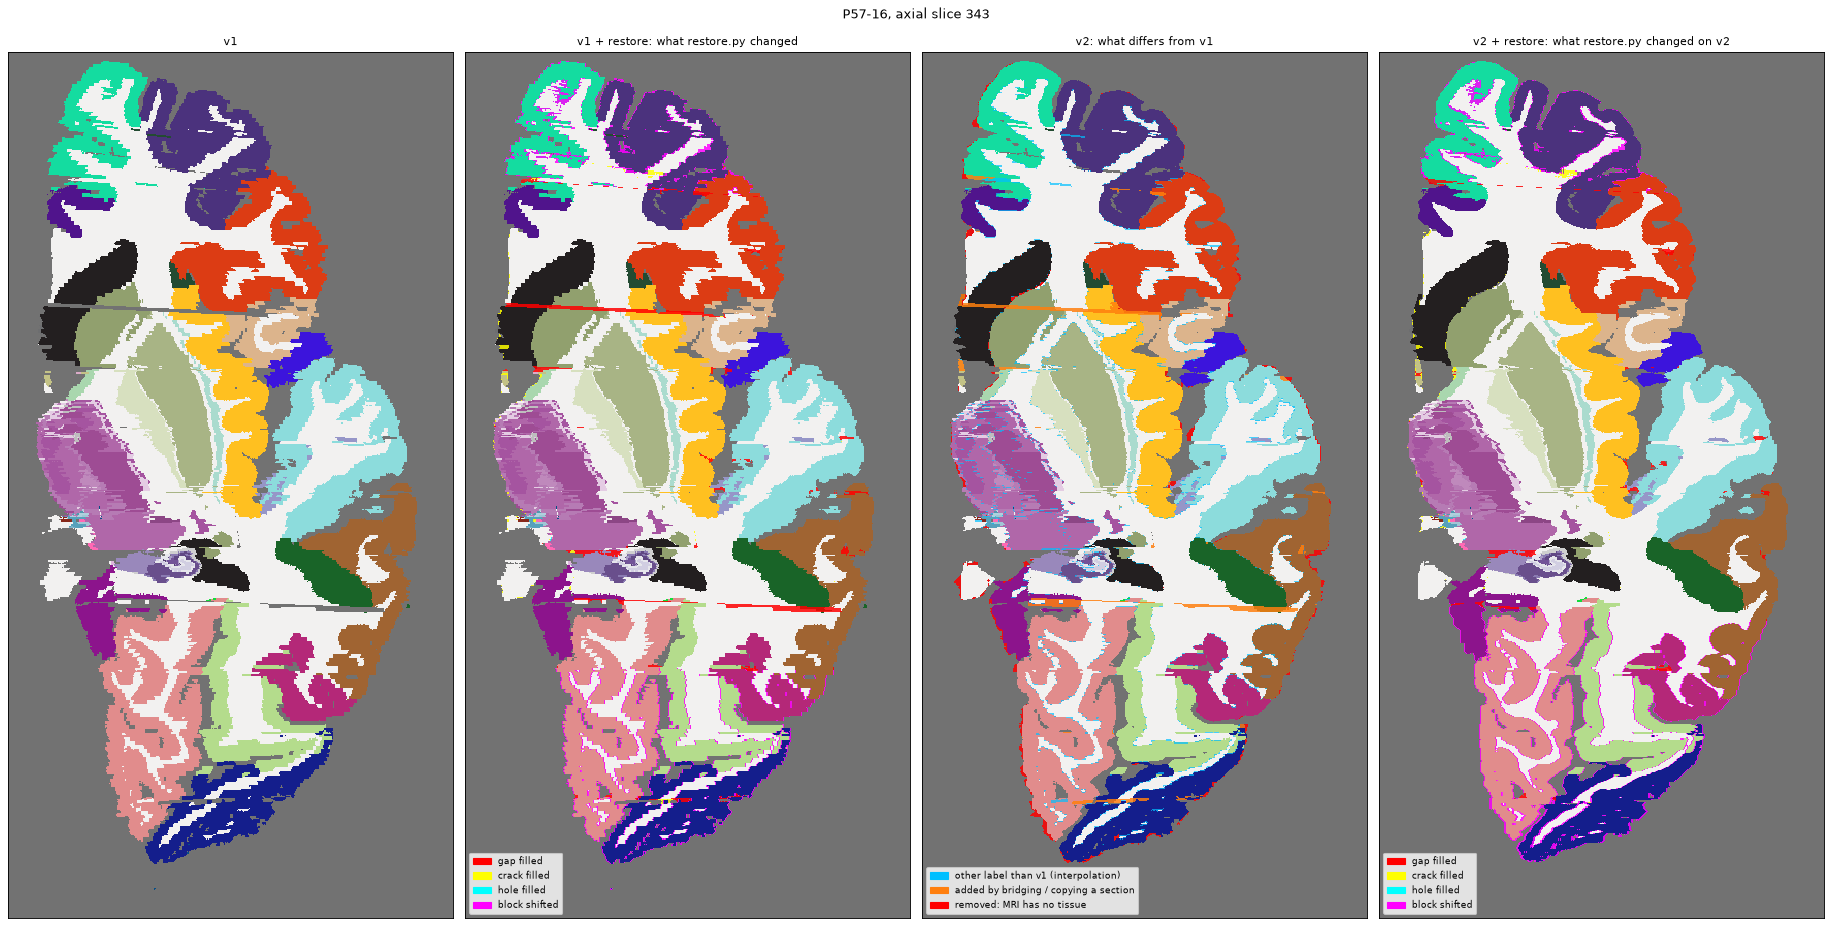

In [3]:
RCOL = {1: ("gap filled", "red"), 2: ("crack filled", "yellow"), 3: ("hole filled", "cyan"), 4: ("block shifted", "magenta")}
VCOL = {"bridged": "tab:orange", "trimmed": "red", "differs": "deepskyblue"}

def change_maps(C, axis=0, index=None, save=None):
    index = int((C.lo[axis] + C.hi[axis]) // 2) if index is None else index
    win = C.full_win(axis)
    h = 23 / 4 * (win[1].stop - win[1].start) / (win[0].stop - win[0].start) + 0.9
    fig, axs = plt.subplots(1, 4, figsize=(23, h))
    show_lab(axs[0], C.plane("v1", axis, index, win), win, "v1")
    show_lab(axs[1], C.plane("v1_restore", axis, index, win), win, "v1 + restore: what restore.py changed")
    st = C.plane("restore_steps", axis, index, win)
    for k, (n, c) in RCOL.items(): overlay(axs[1], st == k, c, win)
    axs[1].legend(handles=[Patch(color=c, label=n) for n, c in RCOL.values()], fontsize=8, loc="lower left")
    v2, v1 = C.plane("v2", axis, index, win), C.plane("v1", axis, index, win); st = C.plane("v2_steps", axis, index, win)
    show_lab(axs[2], v2, win, "v2: what differs from v1")
    overlay(axs[2], (v2 != v1) & (v2 > 0) & (v1 > 0), VCOL["differs"], win, 0.7)
    overlay(axs[2], (st == 2) & (v1 == 0) & (v2 > 0), VCOL["bridged"], win); overlay(axs[2], st == 4, VCOL["trimmed"], win)
    axs[2].legend(handles=[Patch(color=VCOL["differs"], label="other label than v1 (interpolation)"),
                           Patch(color=VCOL["bridged"], label="added by bridging / copying a section"),
                           Patch(color=VCOL["trimmed"], label="removed: MRI has no tissue")], fontsize=8, loc="lower left")
    show_lab(axs[3], C.plane("v2_restore", axis, index, win), win, "v2 + restore: what restore.py changed on v2")
    st = C.plane("v2_restore_steps", axis, index, win)
    for k, (n, c) in RCOL.items(): overlay(axs[3], st == k, c, win)
    axs[3].legend(handles=[Patch(color=c, label=n) for n, c in RCOL.values()], fontsize=8, loc="lower left")
    plt.suptitle(f"{C.case}, {AXNAME[axis]} slice {index}", fontsize=12); plt.tight_layout()
    if save: fig.savefig(os.path.join(FIG, save), dpi=90)
    plt.show()

change_maps(C, 0, save=f"{C.case}_changes_sagittal.png")
change_maps(C, 2, save=f"{C.case}_changes_axial.png")

## 3. Zooms on the typical situations

Each figure shows the same window in the four methods and in the MRI. The windows are chosen
automatically, at the place where the effect named in the title is largest.

### 3.1 Block gaps in white matter and the staircase

Window with the most voxels filled by `restore.py` as "gap", on a sagittal slice (the sections are
seen from their edge, so the staircase of v1 is visible).

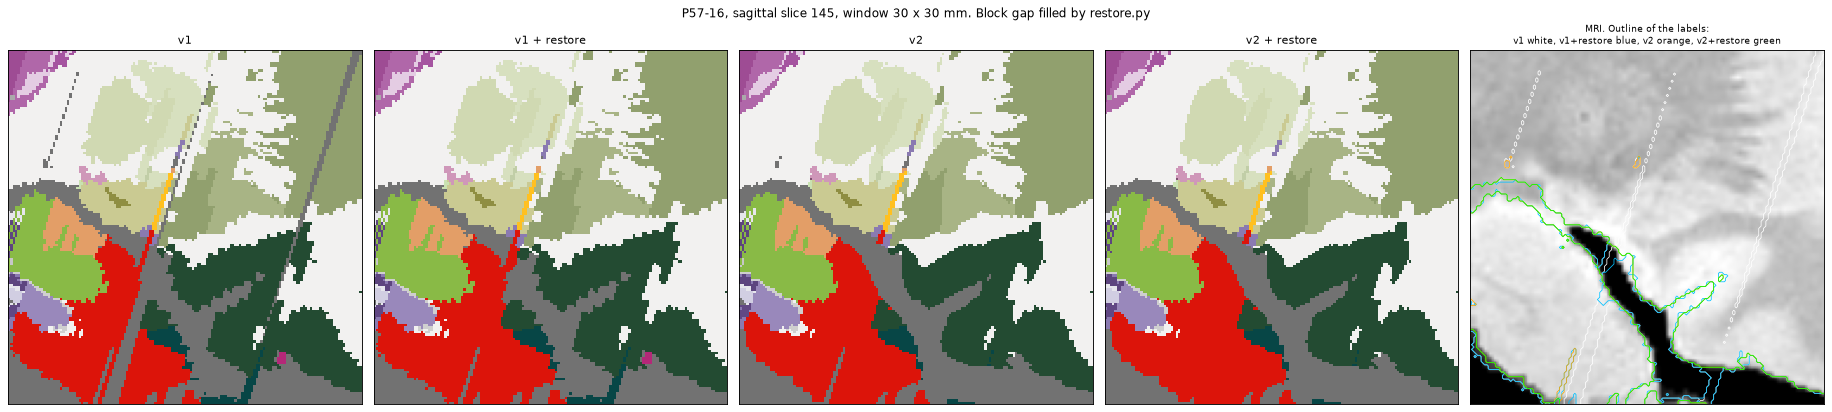

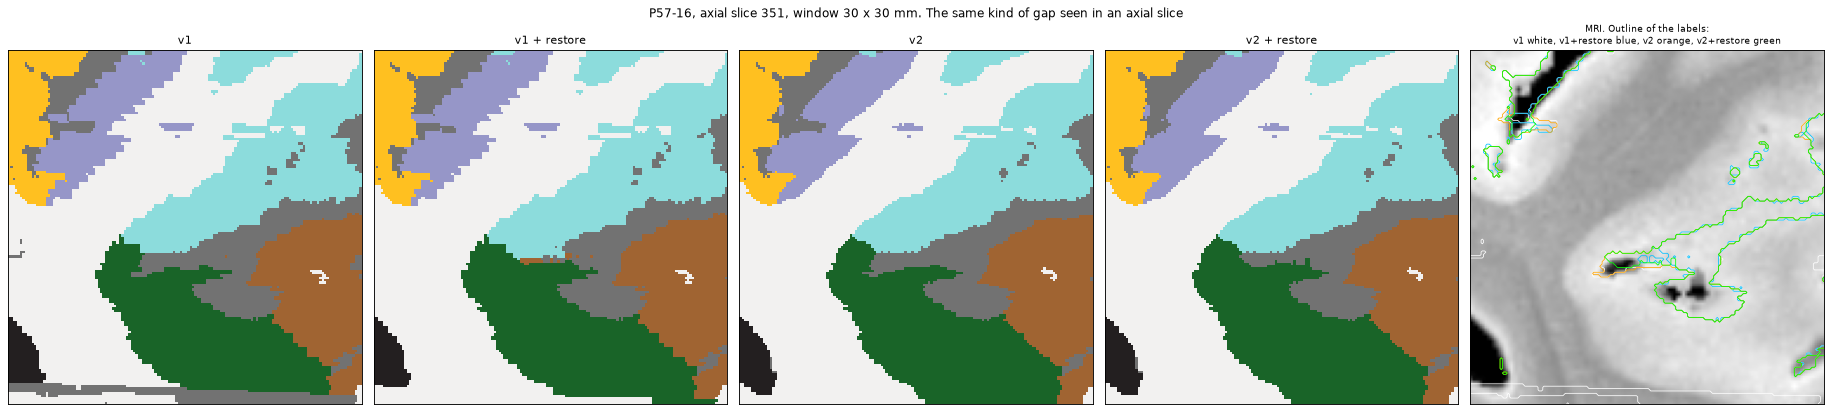

In [4]:
def pick(C, mask3d, axis, size=150):
    i = best_slice(mask3d, axis)
    return i, best_window(np.take(mask3d, i, axis=axis), size)

gap = C.vol["restore_steps"] == 1
i, win = pick(C, gap, 0)
zoom(C, 0, i, win, "Block gap filled by restore.py", save=f"{C.case}_zoom_gap.png")
i, win = pick(C, gap, 2)
zoom(C, 2, i, win, "The same kind of gap seen in an axial slice", save=f"{C.case}_zoom_gap_axial.png")

### 3.2 End of a block: missing sections bridged by v2

Window with the most voxels that v2 adds by copying the last usable section of a block.

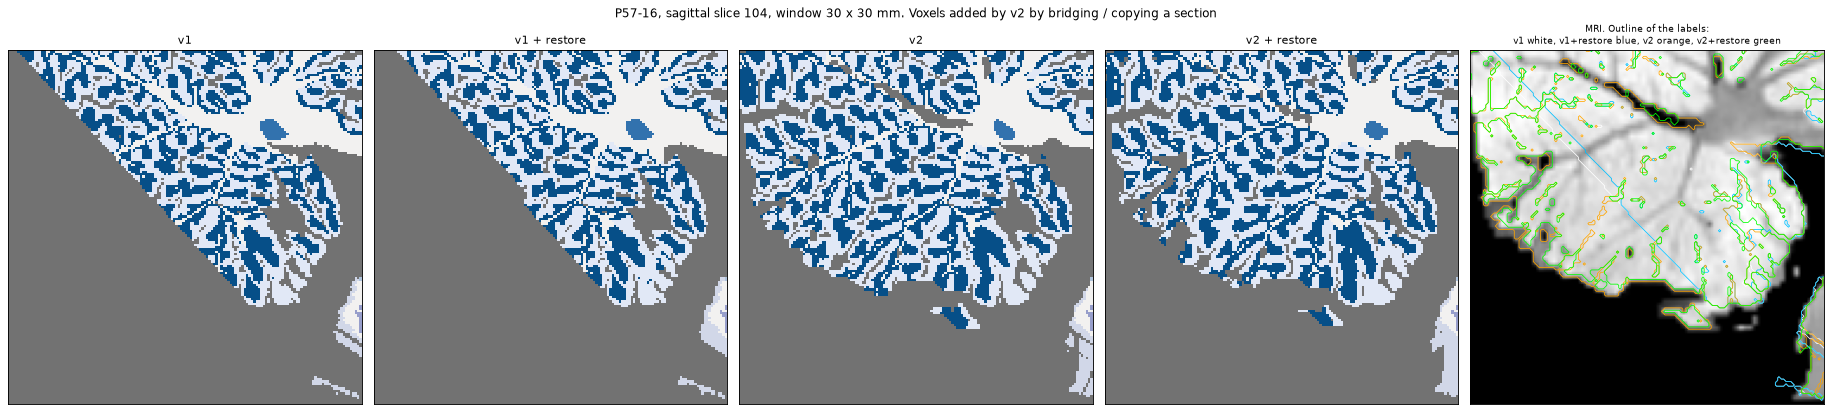

In [5]:
bridged = (C.vol["v2_steps"] == 2) & (C.vol["v1"] == 0) & (C.vol["v2"] > 0)
i, win = pick(C, bridged, 0)
zoom(C, 0, i, win, "Voxels added by v2 by bridging / copying a section", save=f"{C.case}_zoom_bridged.png")

### 3.3 Sulci

The risk of any gap filling is to close the sulci. The windows are placed where each method adds
the most **cortical** voxels to v1. In the MRI panel, a sulcus that is open in the MRI but closed
by a method shows as an outline that crosses the bright (or dark) sulcal space.

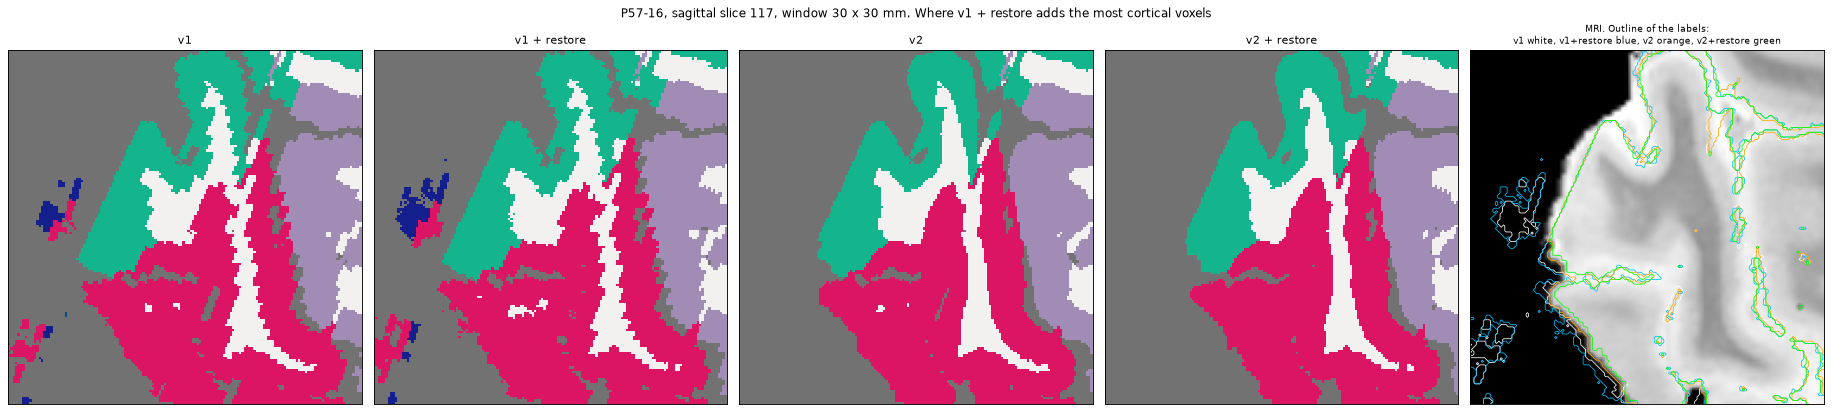

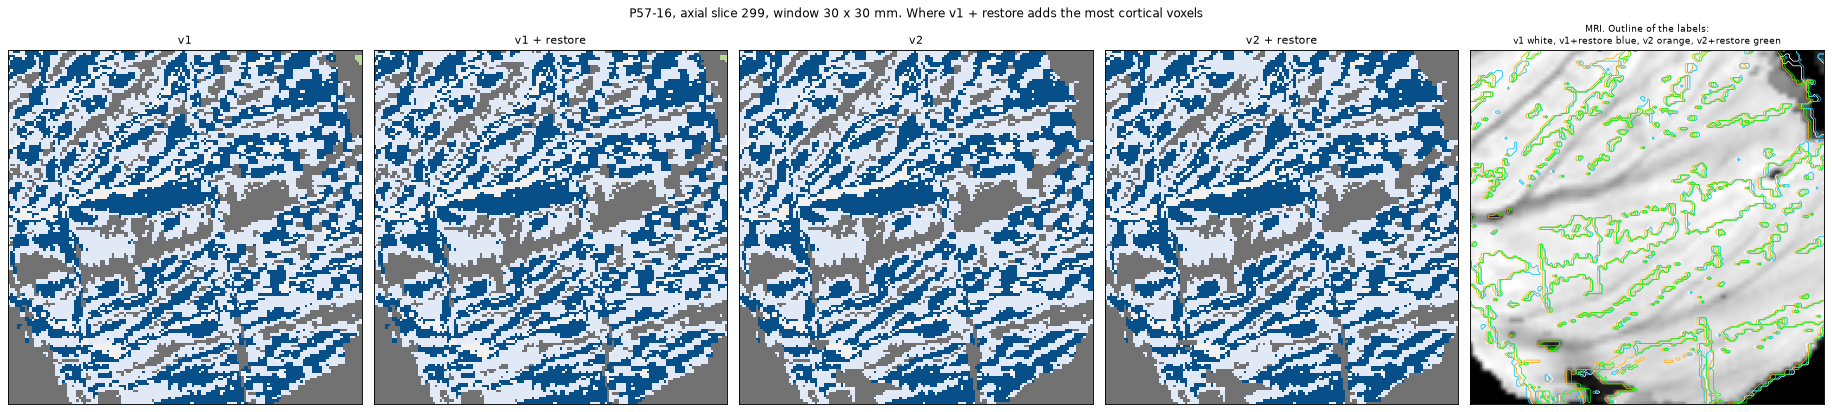

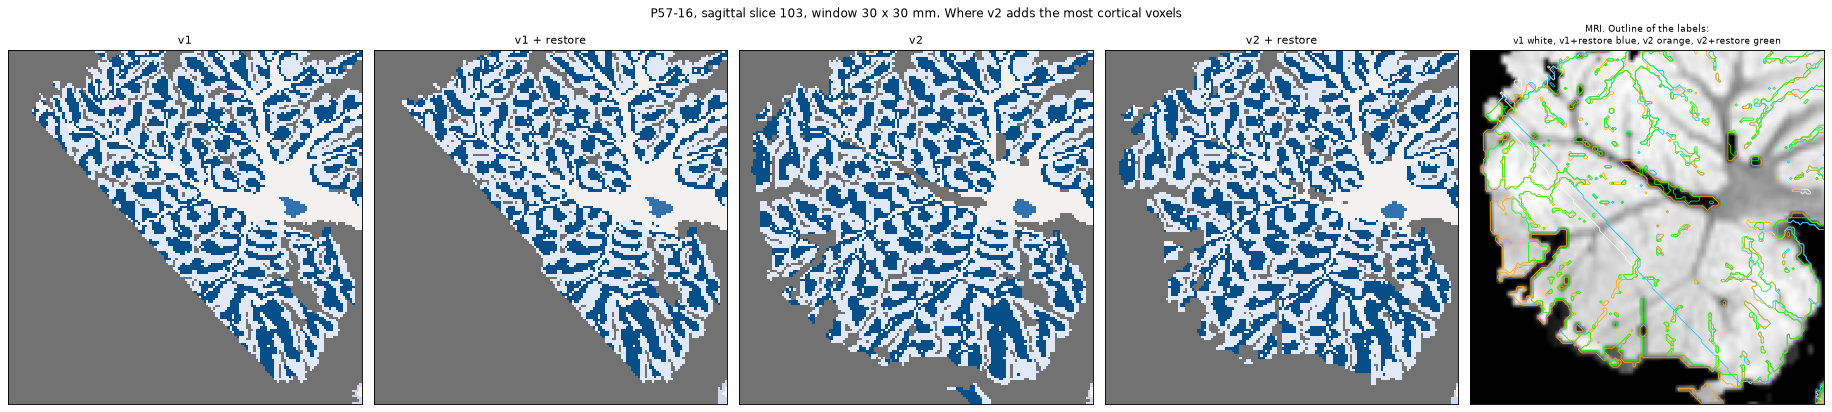

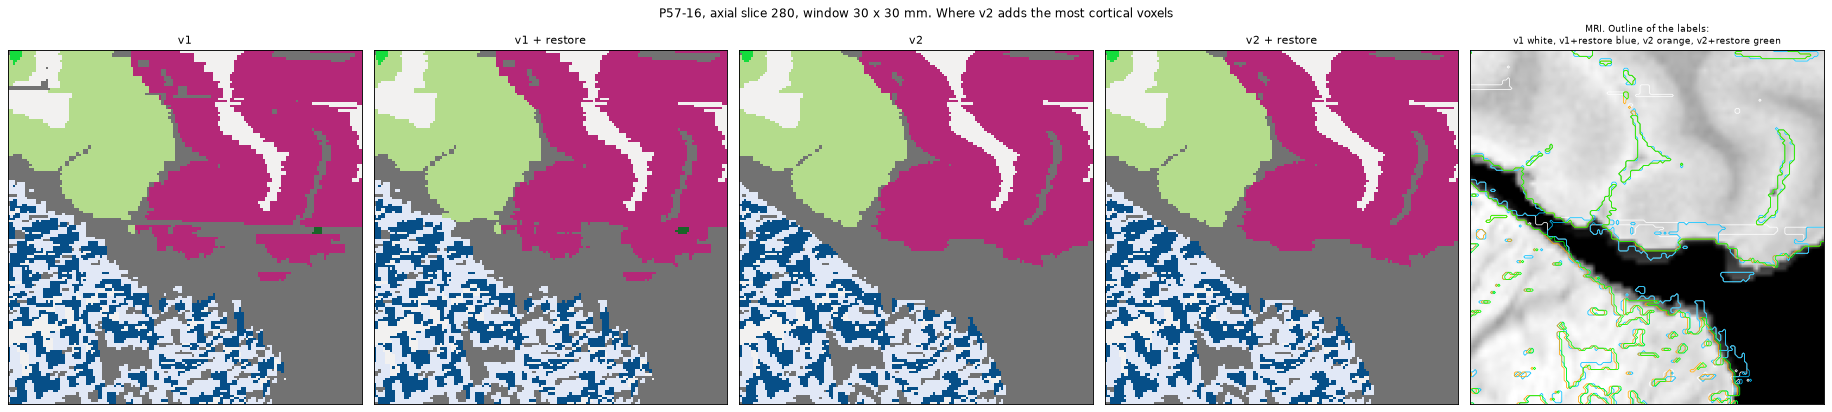

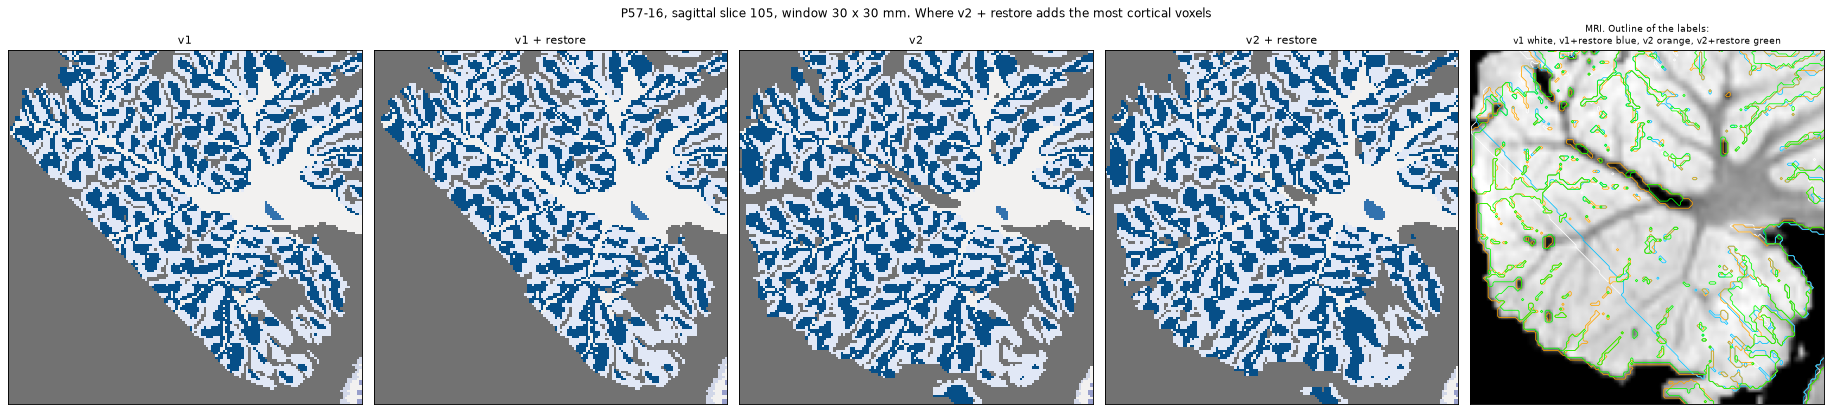

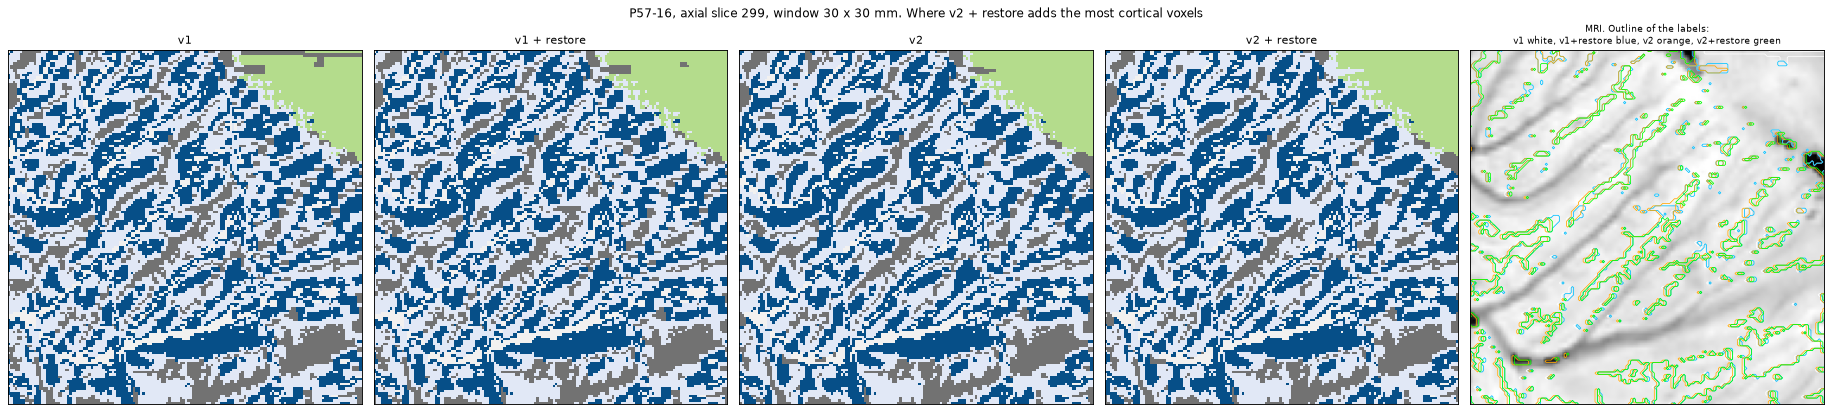

In [6]:
for m in METHODS[1:]:
    add_cx = (C.vol[m] > 0) & (C.vol["v1"] == 0) & IS_CORTEX[C.vol[m]]
    for axis in (0, 2):
        i, win = pick(C, add_cx, axis)
        zoom(C, axis, i, win, f"Where {NAME[m]} adds the most cortical voxels", save=f"{C.case}_zoom_cortex_{m}_{AXNAME[axis]}.png")

### 3.4 Labels removed by v2 where the MRI has no tissue

`v2 + restore` inherits this trimming from v2.

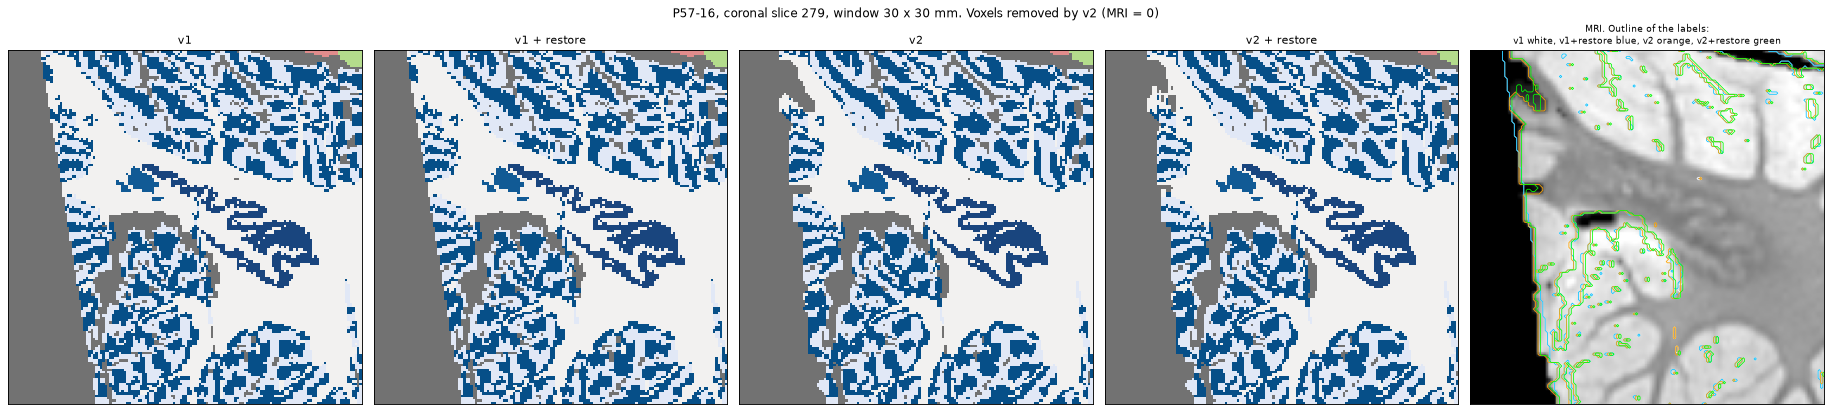

In [7]:
trim = C.vol["v2_steps"] == 4
i, win = pick(C, trim, 1)
zoom(C, 1, i, win, "Voxels removed by v2 (MRI = 0)", save=f"{C.case}_zoom_trim.png")

### 3.5 Cracks and holes that no method closes

Window with the most unlabelled voxels enclosed in tissue (cavities) that are still unlabelled in
the three candidates.

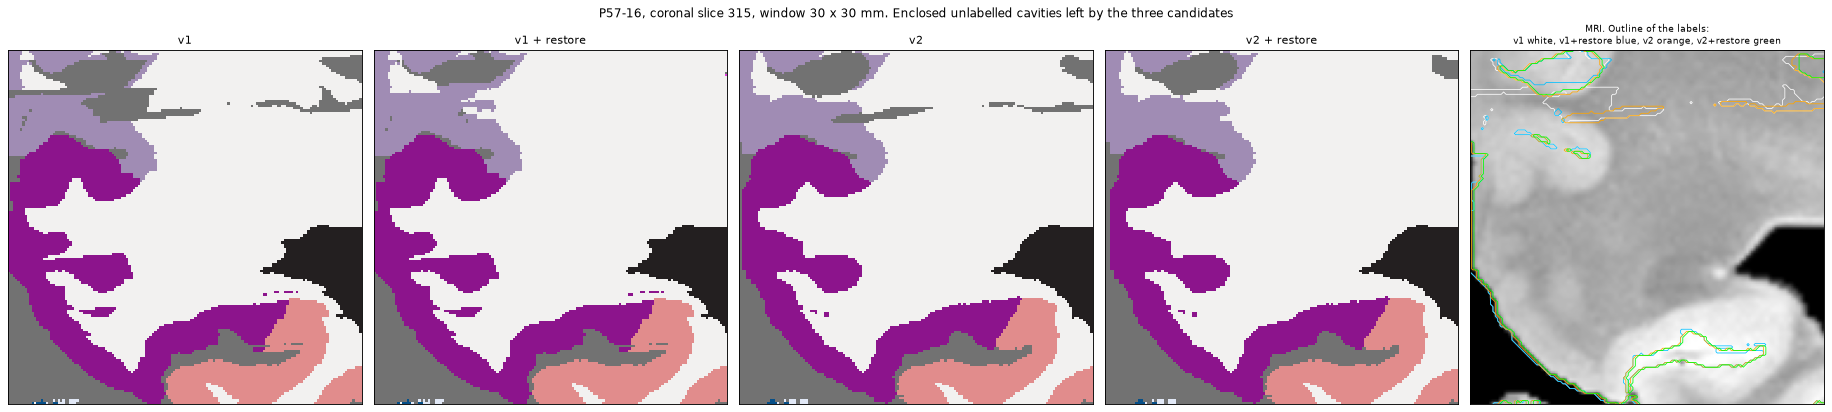

In [8]:
def enclosed(seg):
    return ndi.binary_fill_holes(seg > 0) & (seg == 0)
left = enclosed(C.vol["v1_restore"]) & enclosed(C.vol["v2"]) & enclosed(C.vol["v2_restore"])
i, win = pick(C, left, 1)
zoom(C, 1, i, win, "Enclosed unlabelled cavities left by the three candidates", save=f"{C.case}_zoom_holes.png")
del left

### 3.6 Small structures whose volume changes the most

From `label_ranking_*.csv` (quantitative notebook): for each candidate, the label with the largest
relative volume change that exists in this case with at least 2 mm³. The label is painted in
magenta in the four methods; the window is centred on it.

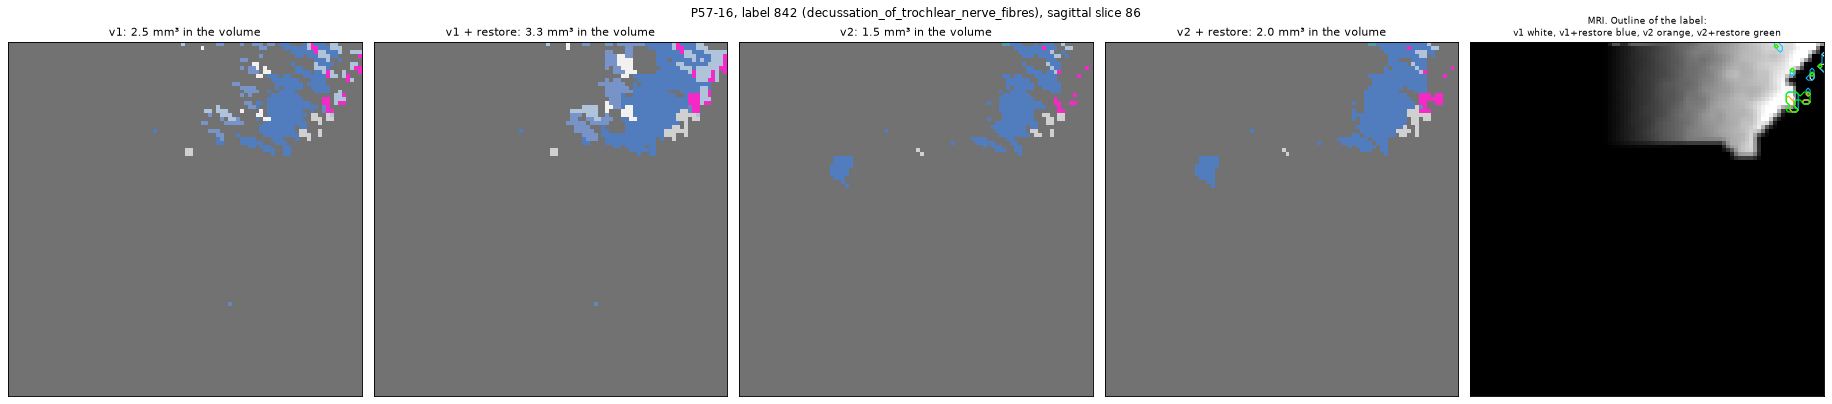

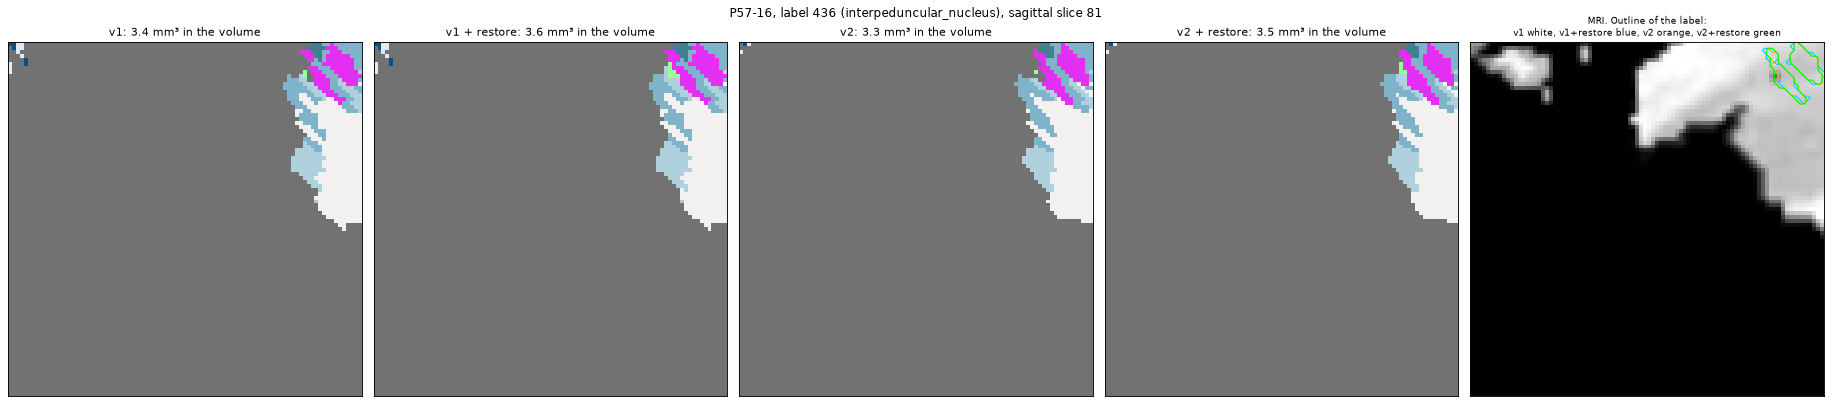

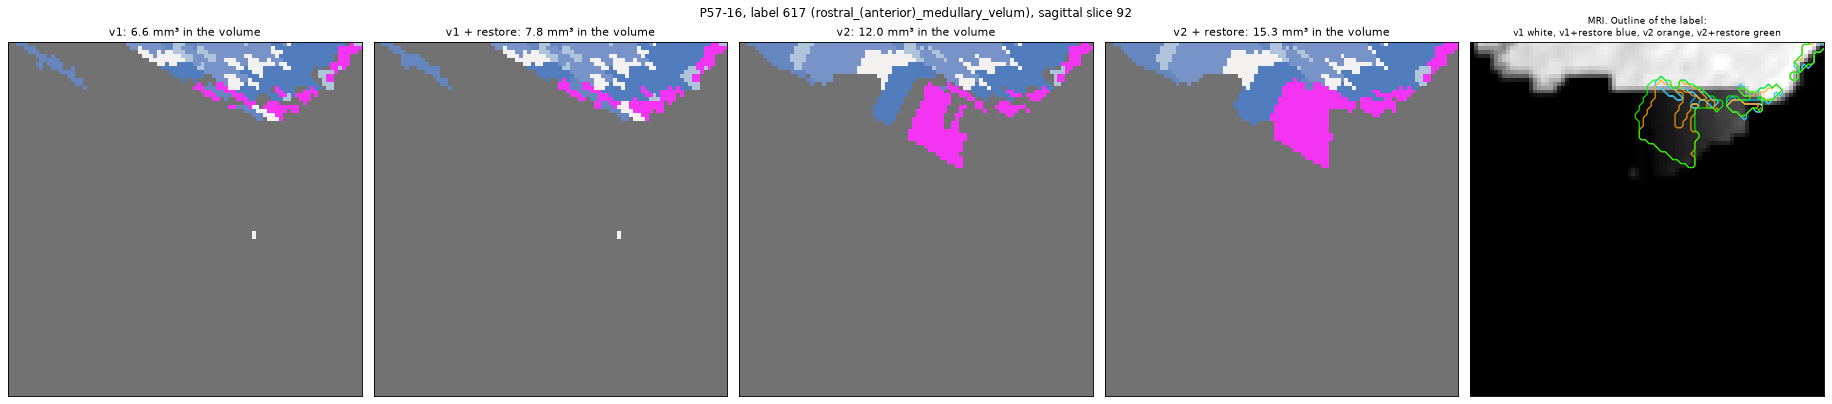

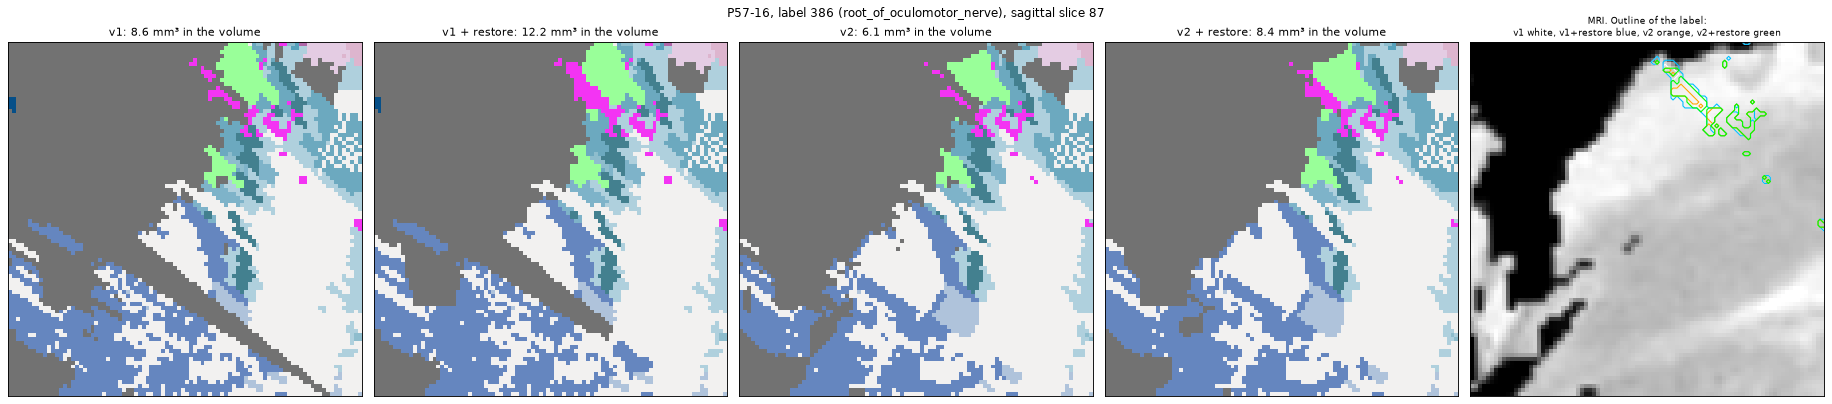

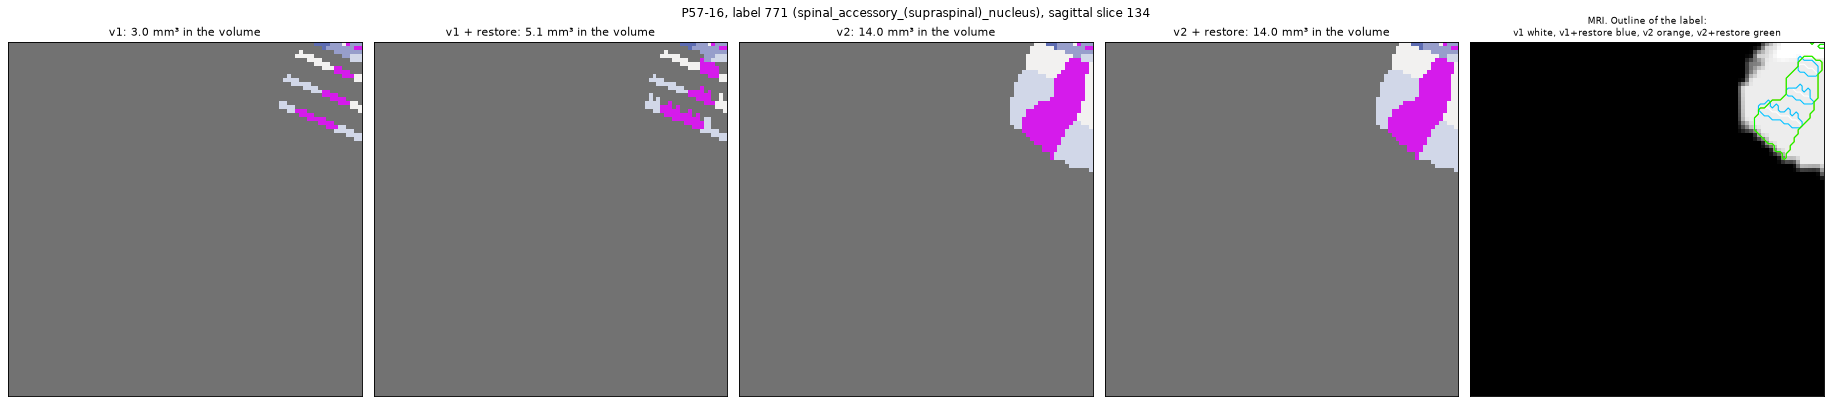

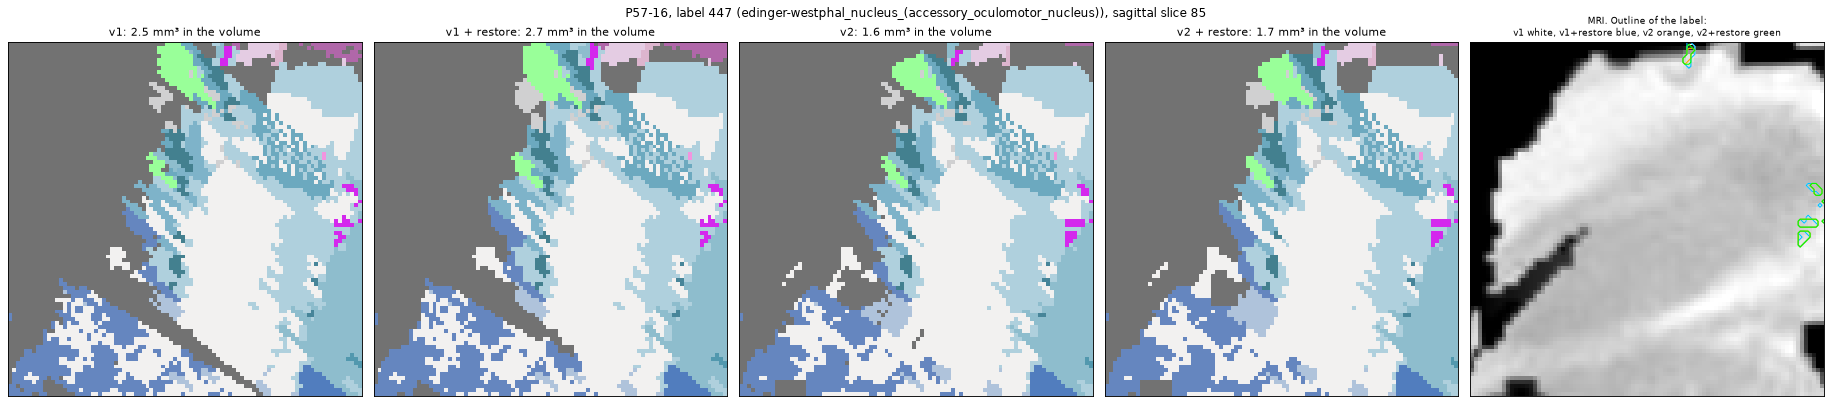

In [9]:
vol = pd.read_csv(os.path.join(T, "volumes.csv"))

def show_label(C, l, axis, size=90, save=None):
    masks = {m: C.vol[m] == l for m in METHODS}
    union = masks["v1"] | masks["v1_restore"] | masks["v2"] | masks["v2_restore"]
    i, win = pick(C, union, axis, size)
    fig, axs = plt.subplots(1, 5, figsize=(23, 5.2))
    v = vol[(vol.case == C.case) & (vol.label == l)].set_index("method").mm3
    for ax, m in zip(axs, METHODS):
        show_lab(ax, C.plane(m, axis, i, win), win, f"{NAME[m]}: {v.get(m, 0):.1f} mm³ in the volume")
        overlay(ax, np.take(masks[m], i, axis=axis)[win], "magenta", win, 0.75)
    mr = C.mri_plane(axis, i, win)
    axs[4].imshow(mr.T, origin="lower", cmap="gray", extent=ext(win), vmax=np.percentile(mr, 99.5)); axs[4].set_xticks([]); axs[4].set_yticks([])
    for m in METHODS:
        if np.take(masks[m], i, axis=axis)[win].any():
            axs[4].contour(np.take(masks[m], i, axis=axis)[win].T, [0.5], colors=OUTLINE[m], linewidths=1, extent=ext(win))
    axs[4].set_title("MRI. Outline of the label:\n" + OUTLINE_TXT, fontsize=8)
    plt.suptitle(f"{C.case}, label {l} ({NAMES.get(l, '?')}), {AXNAME[axis]} slice {i}", fontsize=11); plt.tight_layout()
    if save: fig.savefig(os.path.join(FIG, save), dpi=110)
    plt.show()

here = vol[(vol.case == C.case) & (vol.method == "v1") & (vol.mm3 >= 2)].label
shown = []
for m in ("v2", "v1_restore", "v2_restore"):
    r = pd.read_csv(os.path.join(T, f"label_ranking_{m}.csv"))
    r = r[r.label.isin(here) & ~r.label.isin(shown)]
    for l in r.label.head(2):
        shown.append(int(l))
        show_label(C, int(l), 0, save=f"{C.case}_label_{int(l)}.png")

## 4. The other four cases

Change maps and the most informative zooms (largest gap in two views, bridged sections, where each method adds
the most cortical voxels, labels removed by v2) for the other hemispheres.

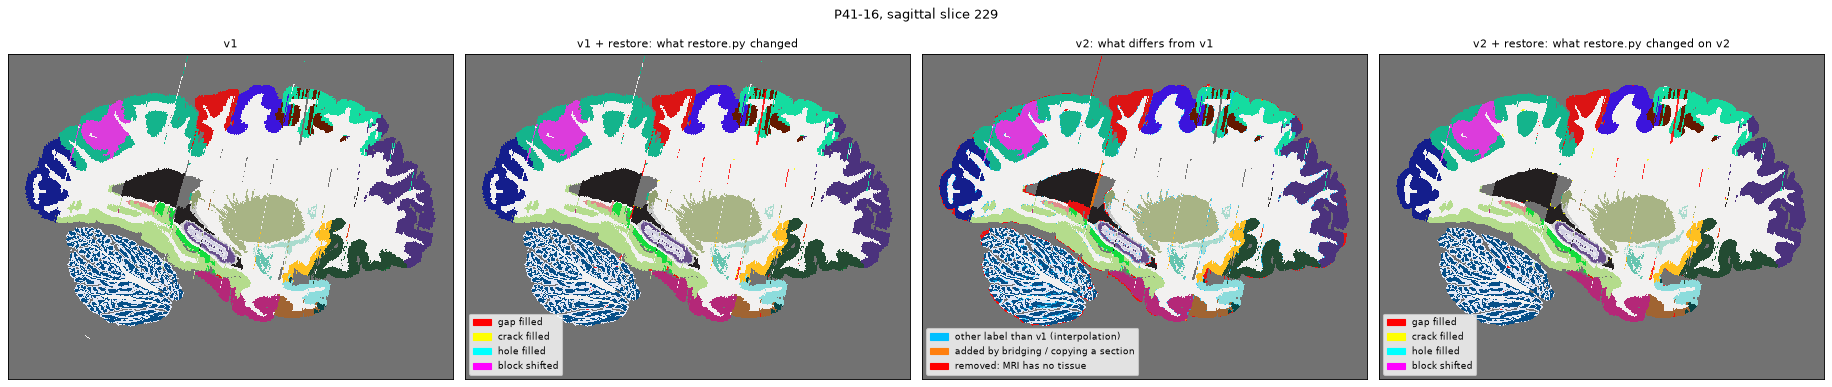

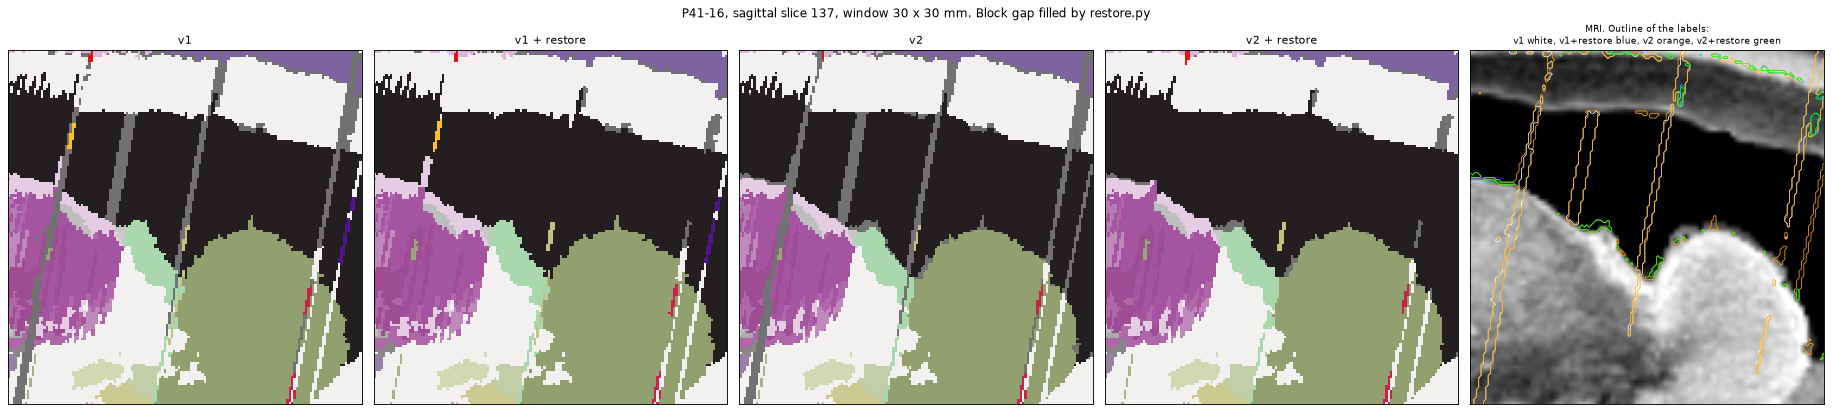

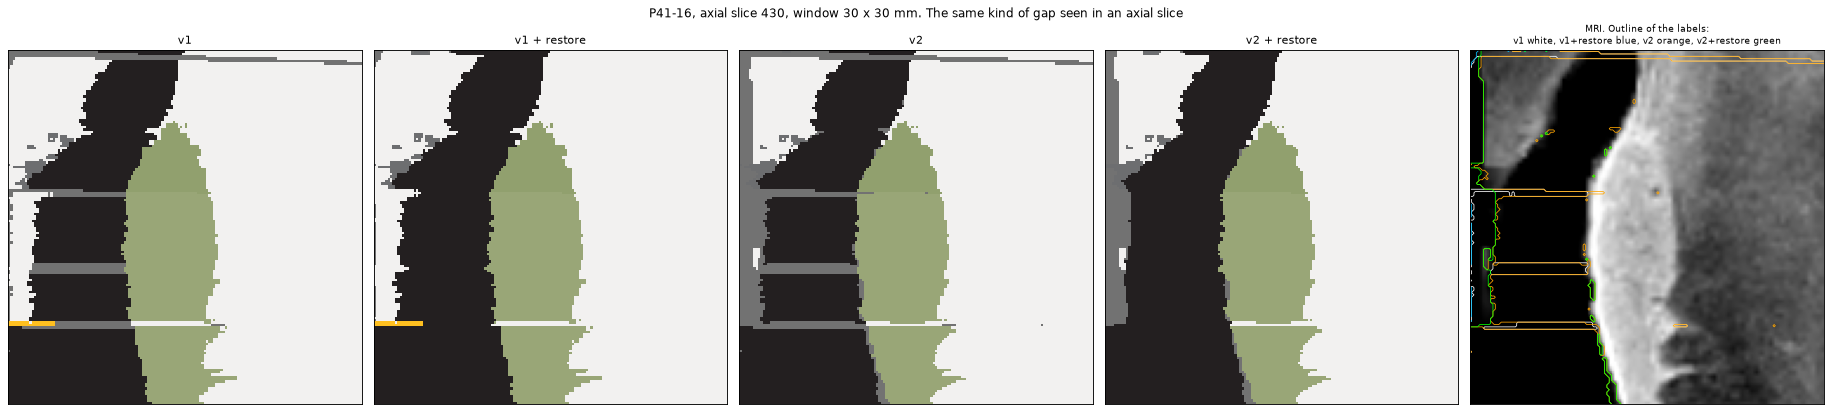

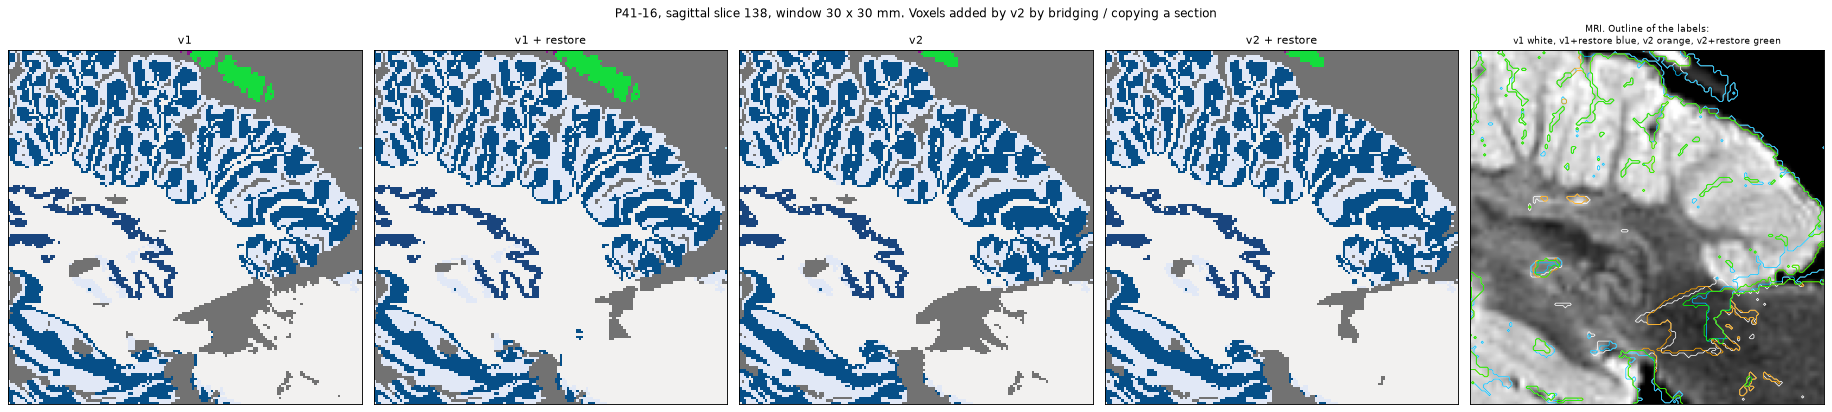

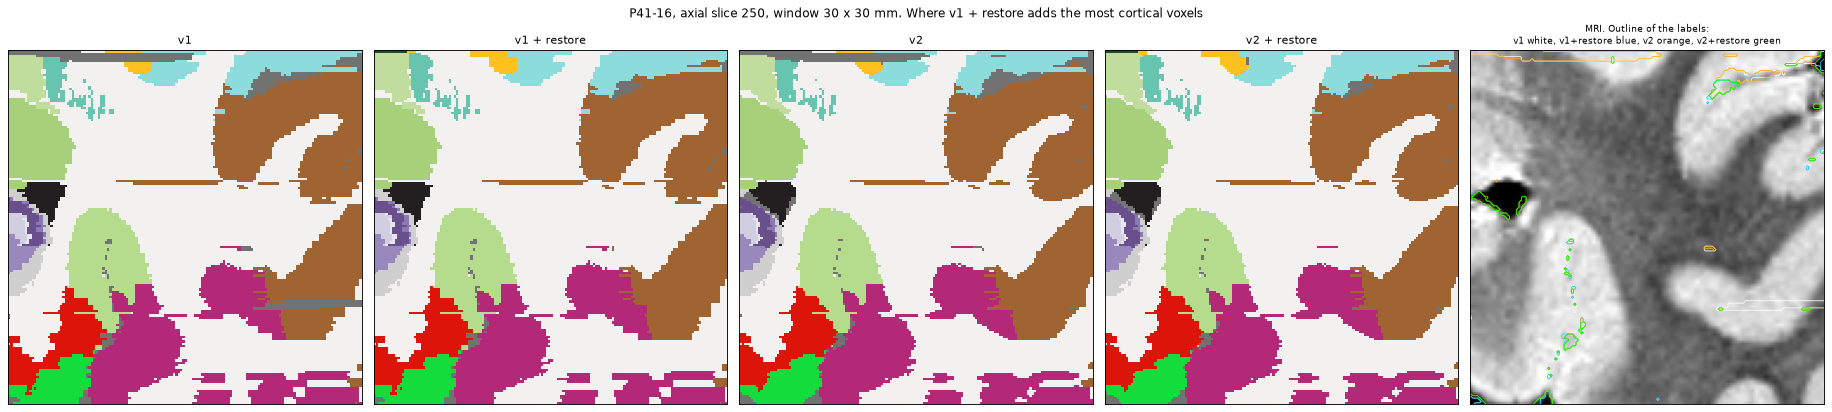

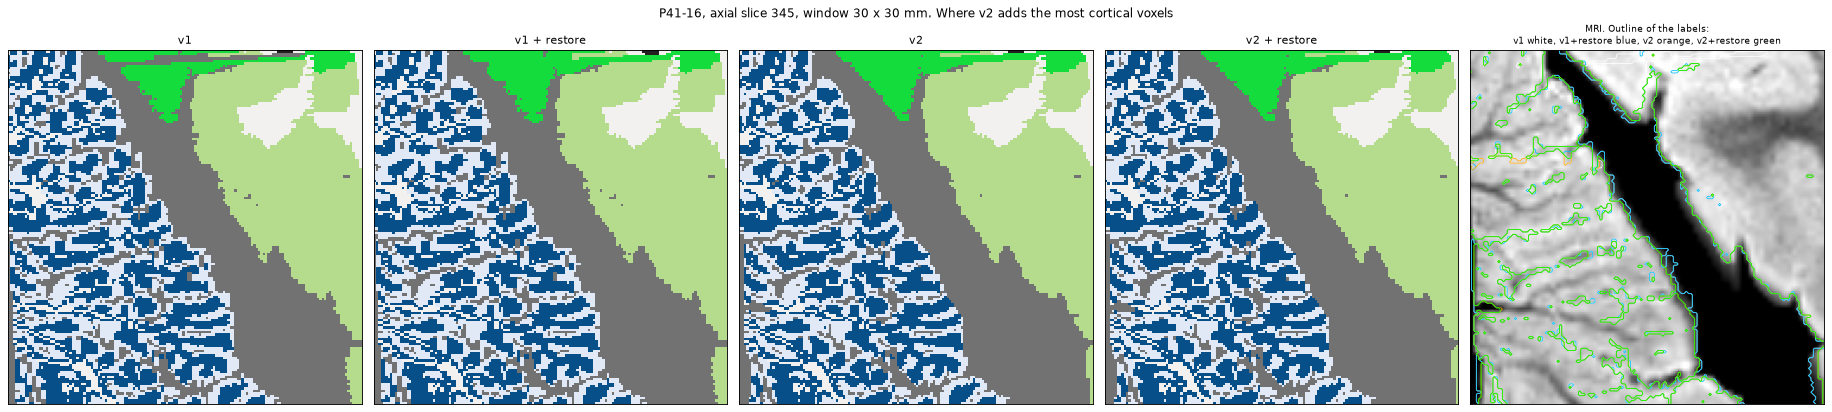

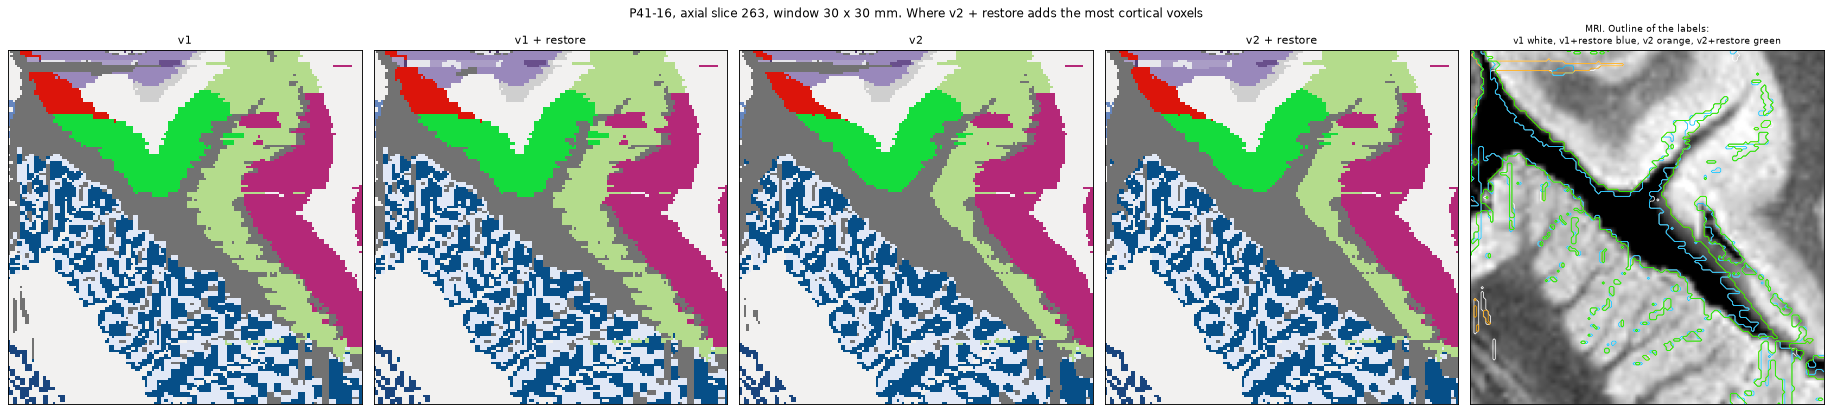

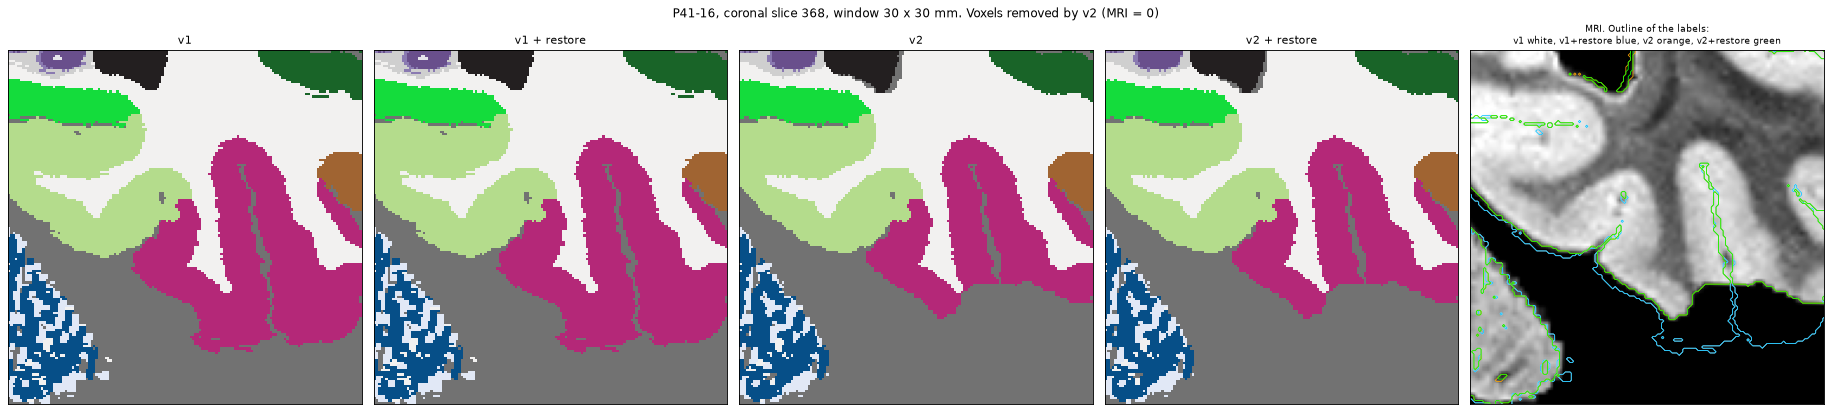

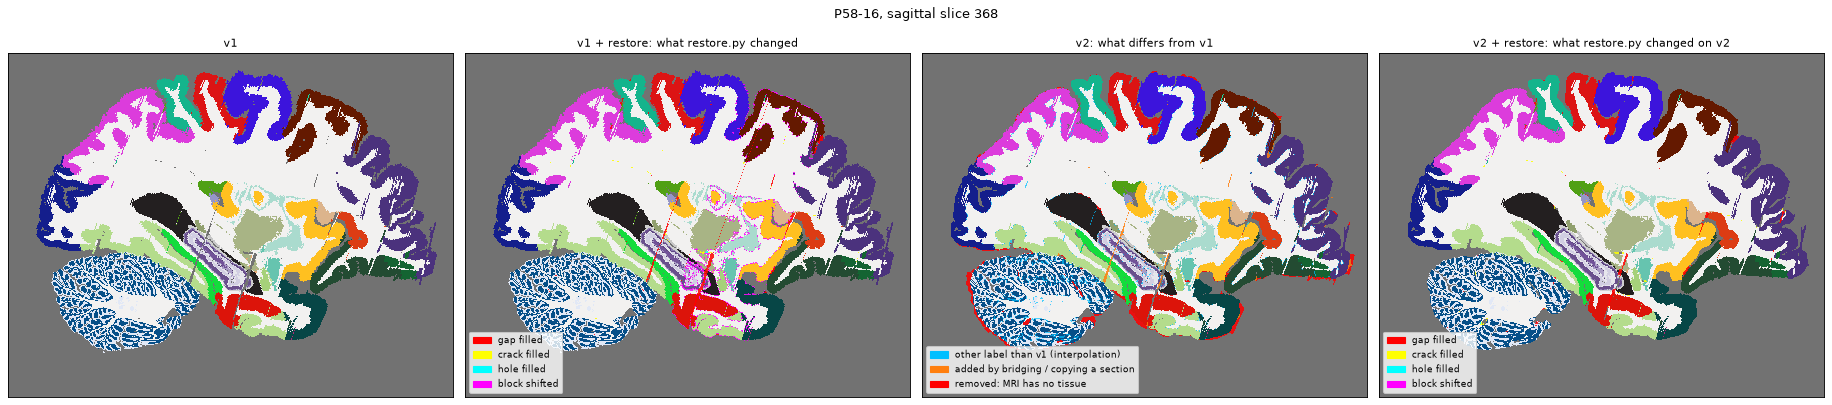

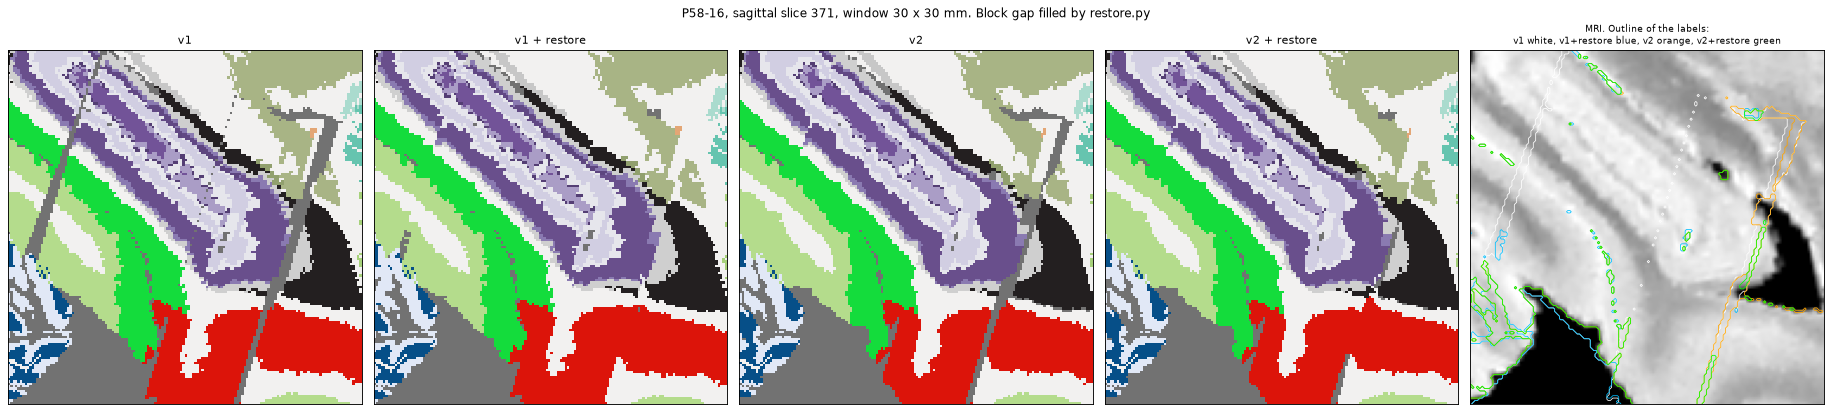

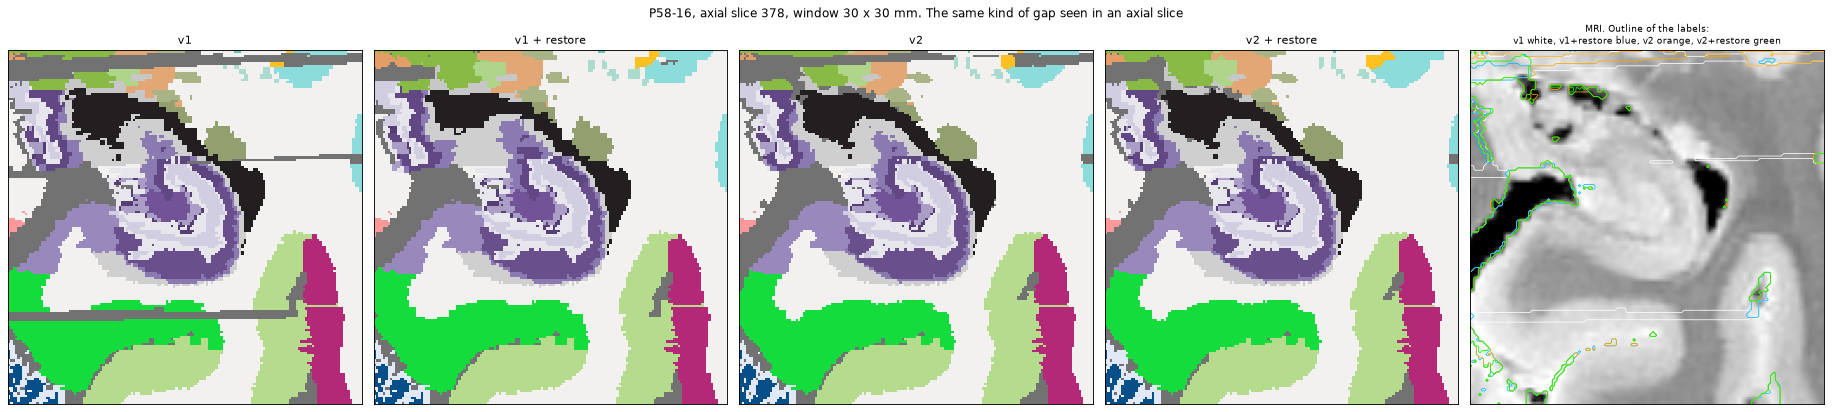

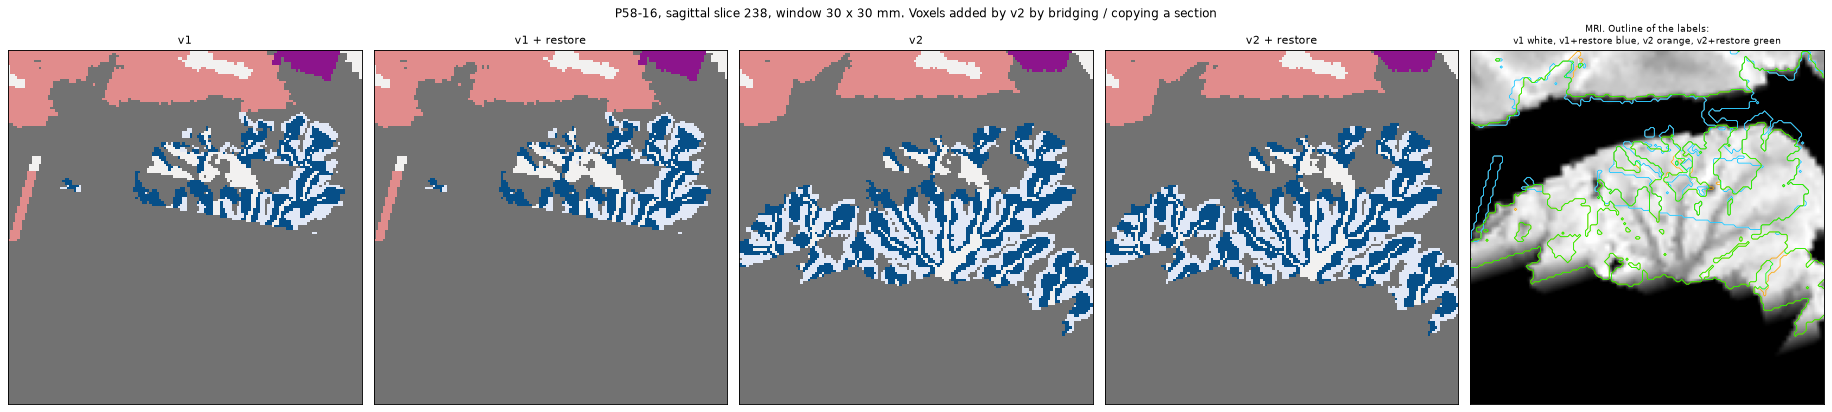

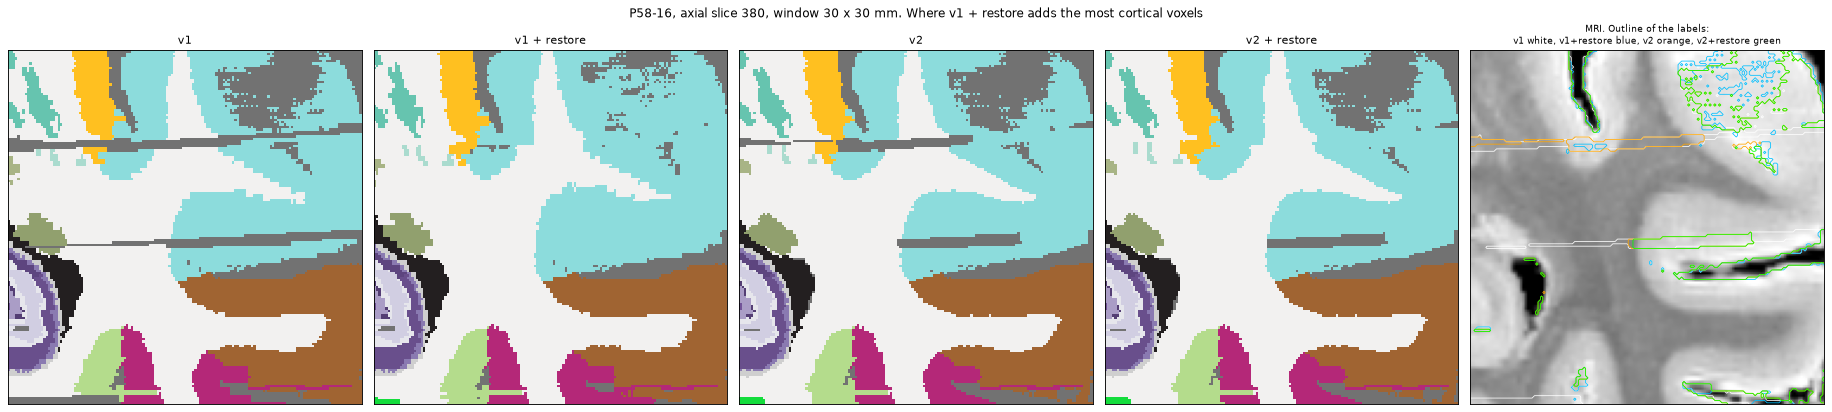

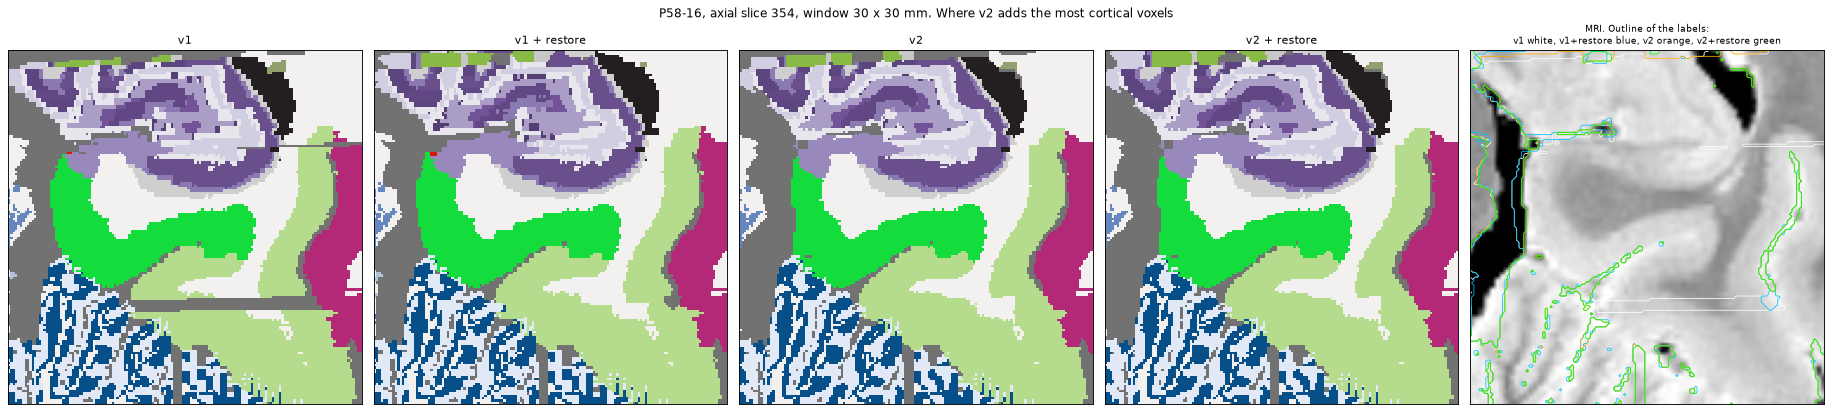

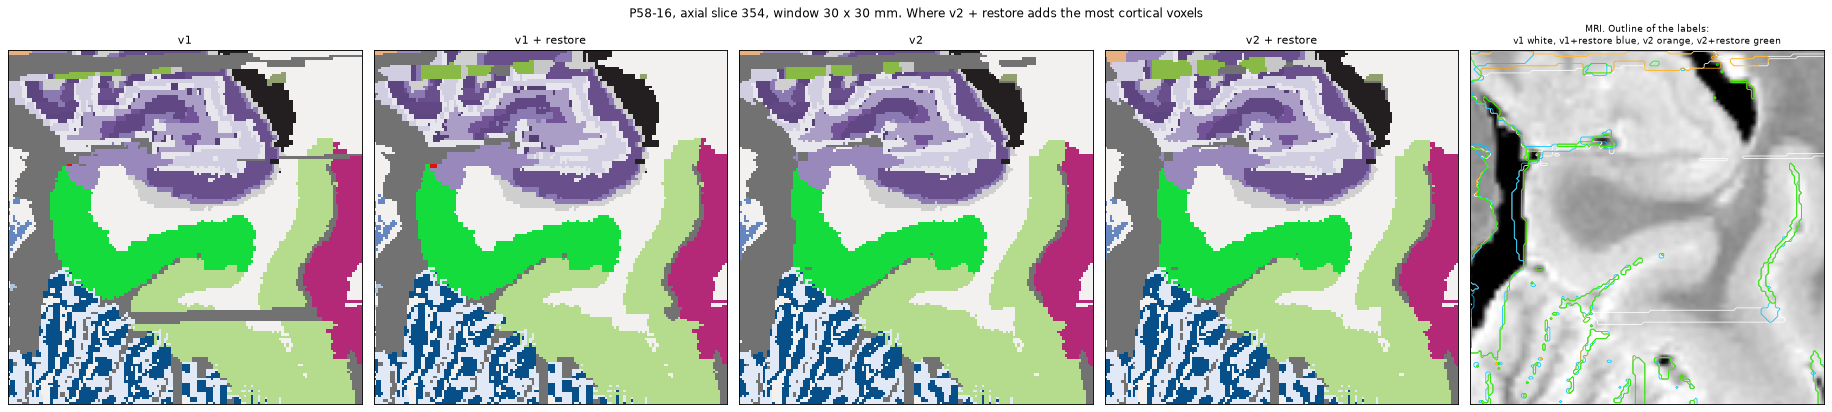

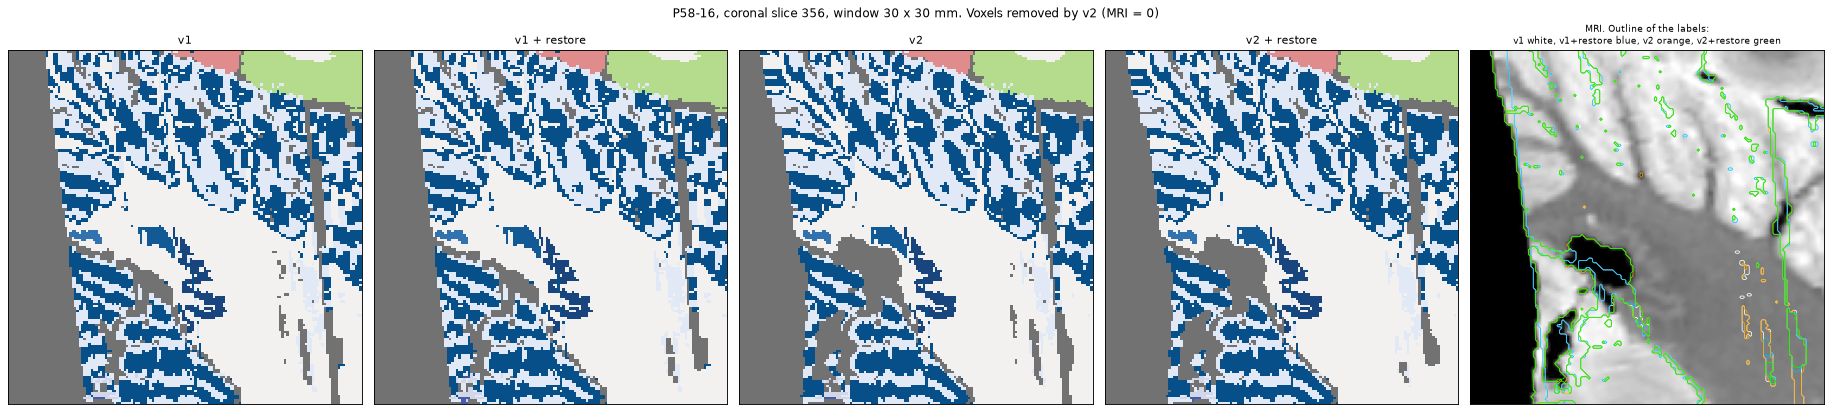

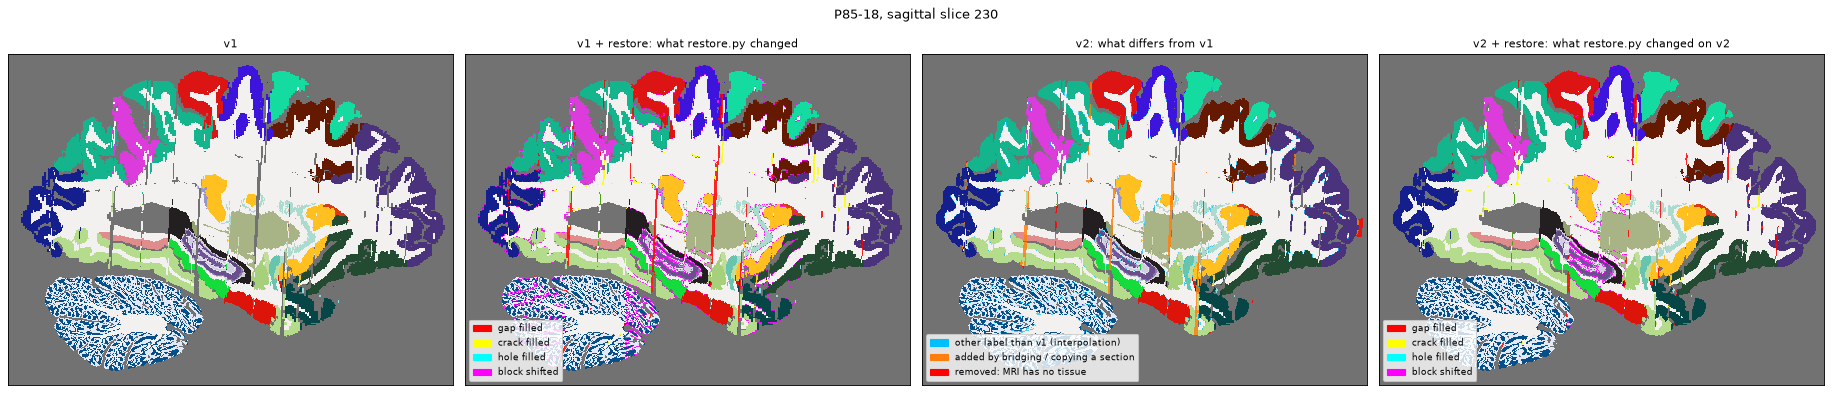

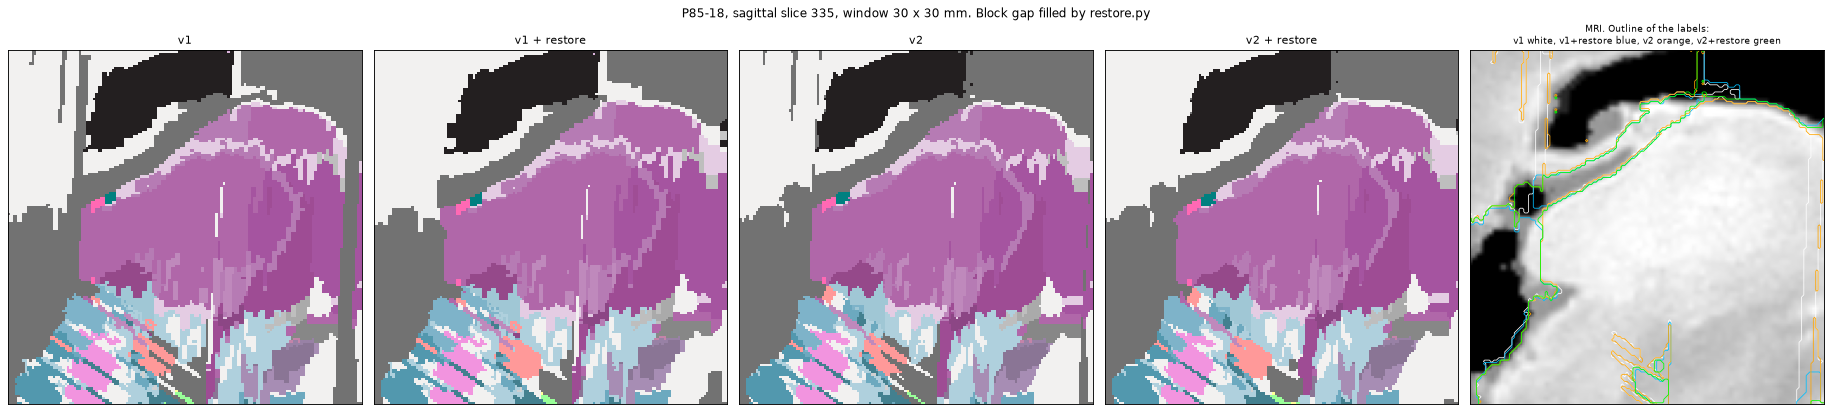

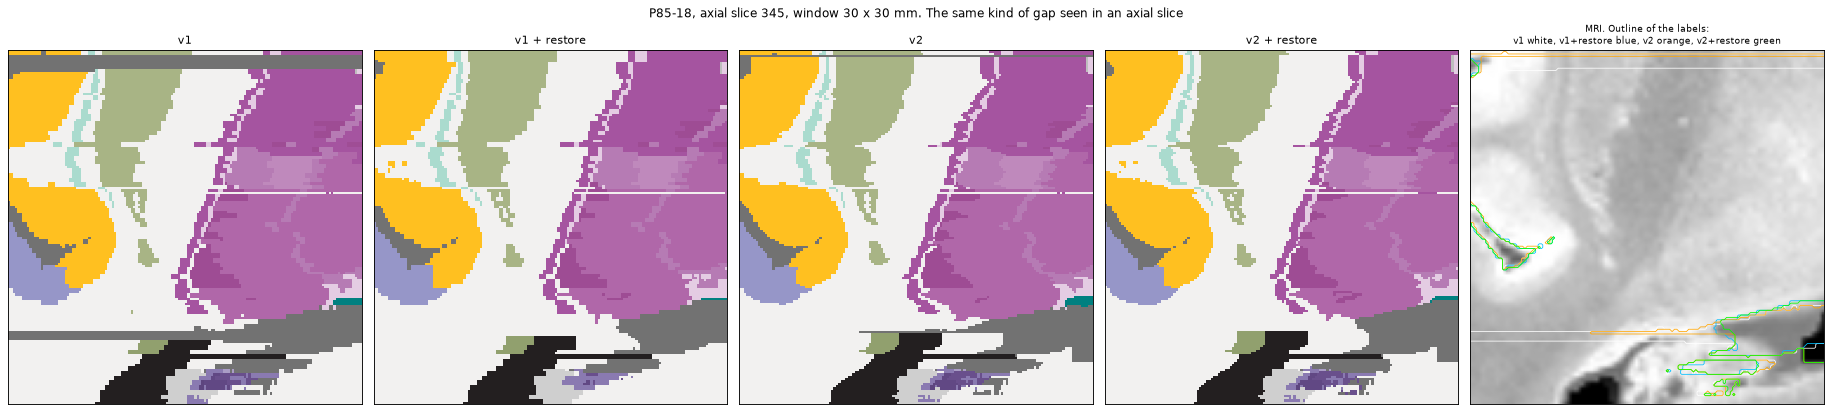

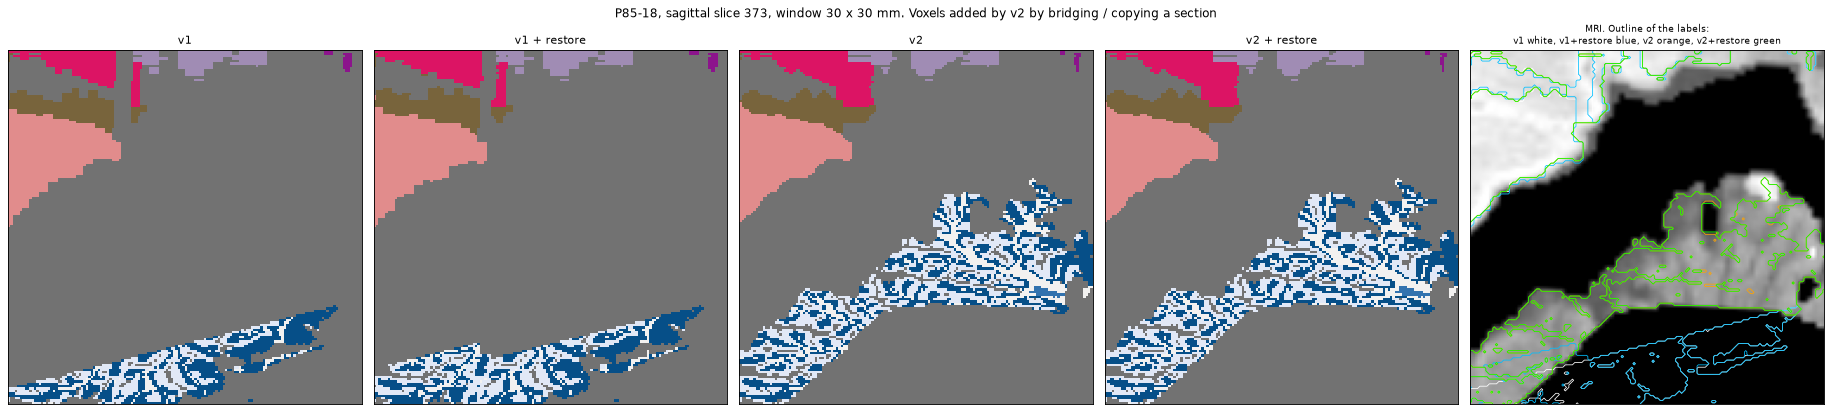

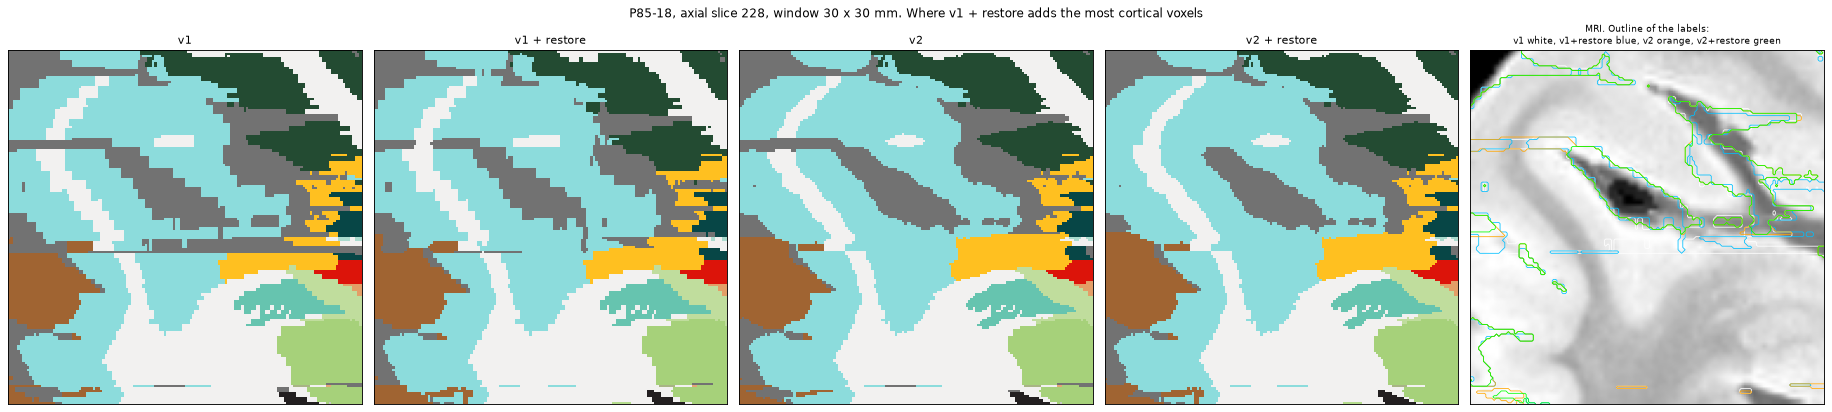

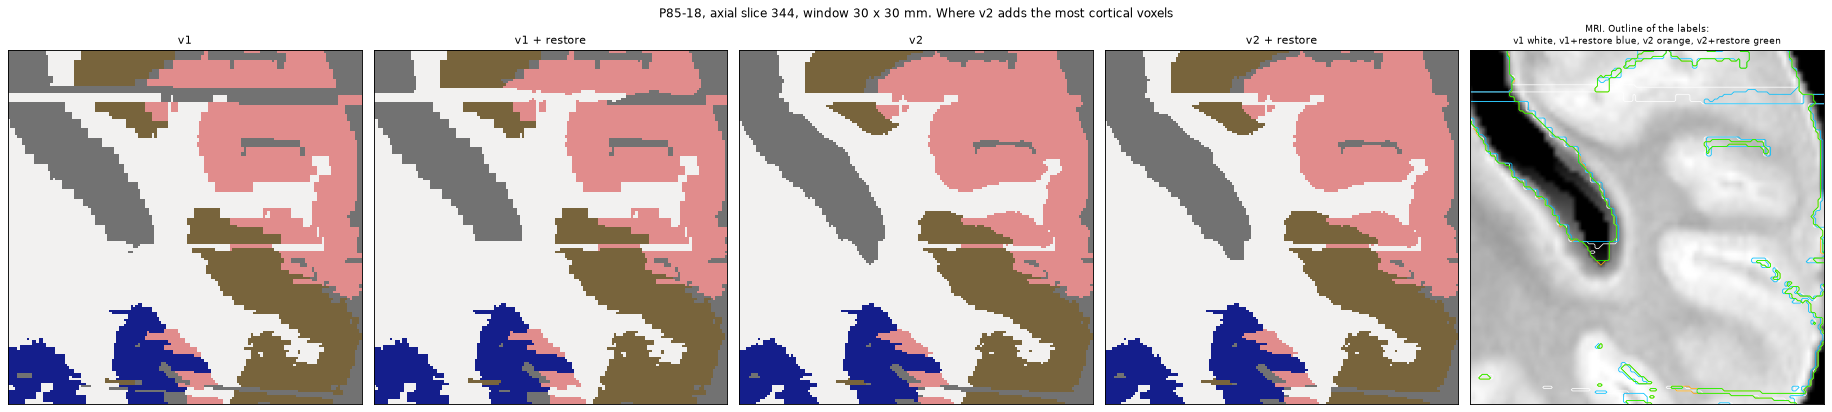

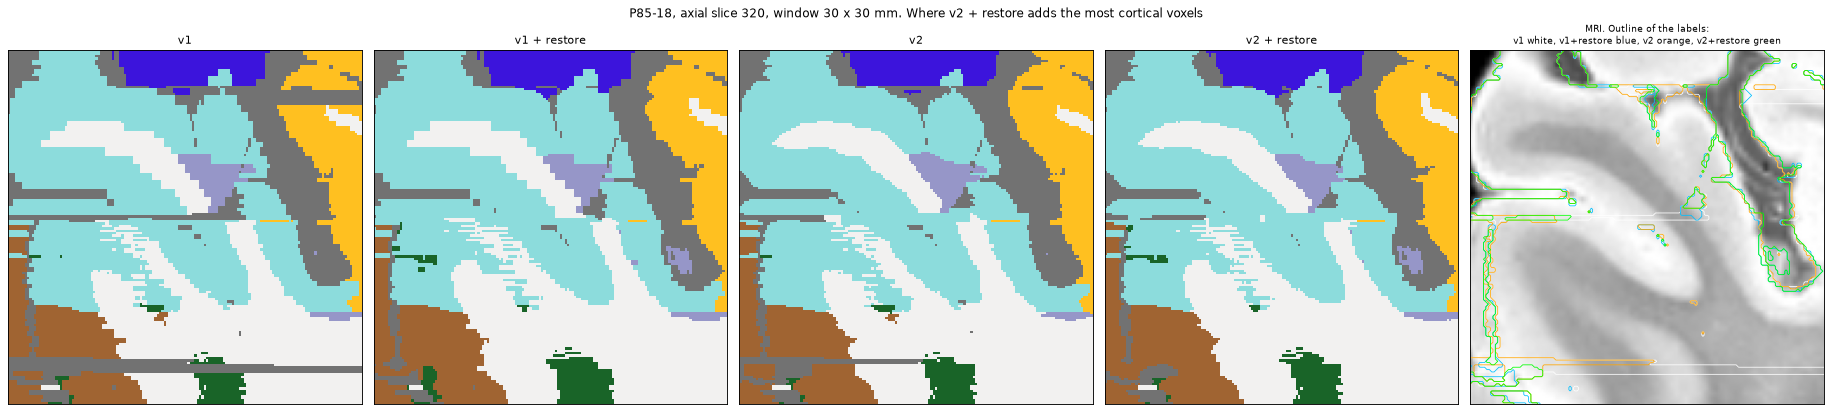

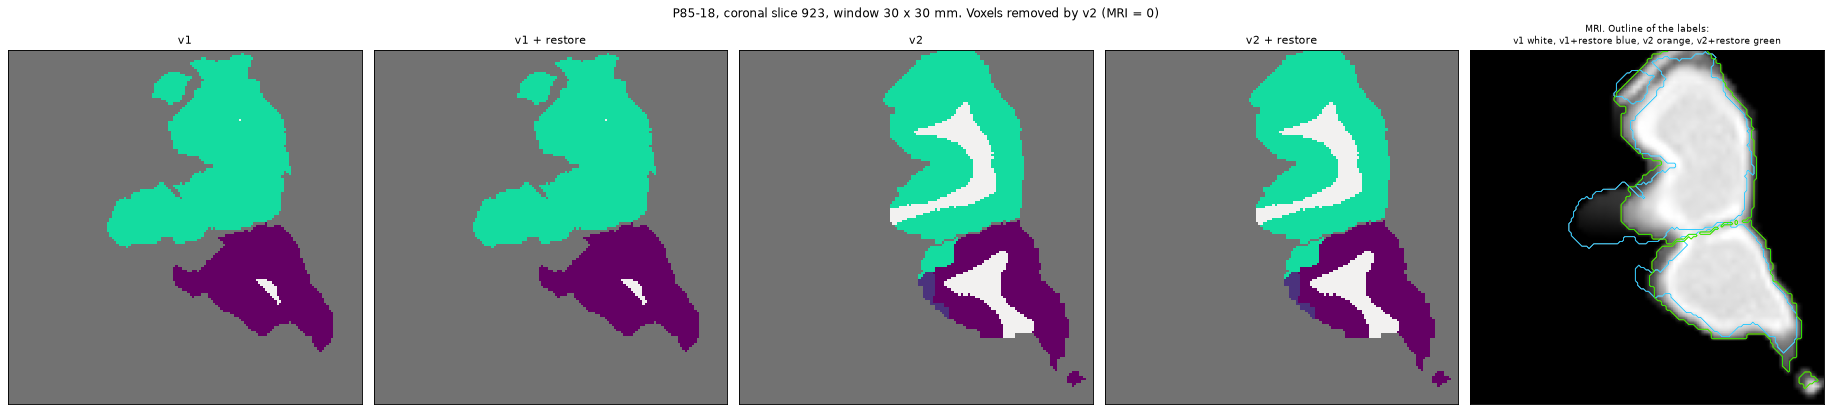

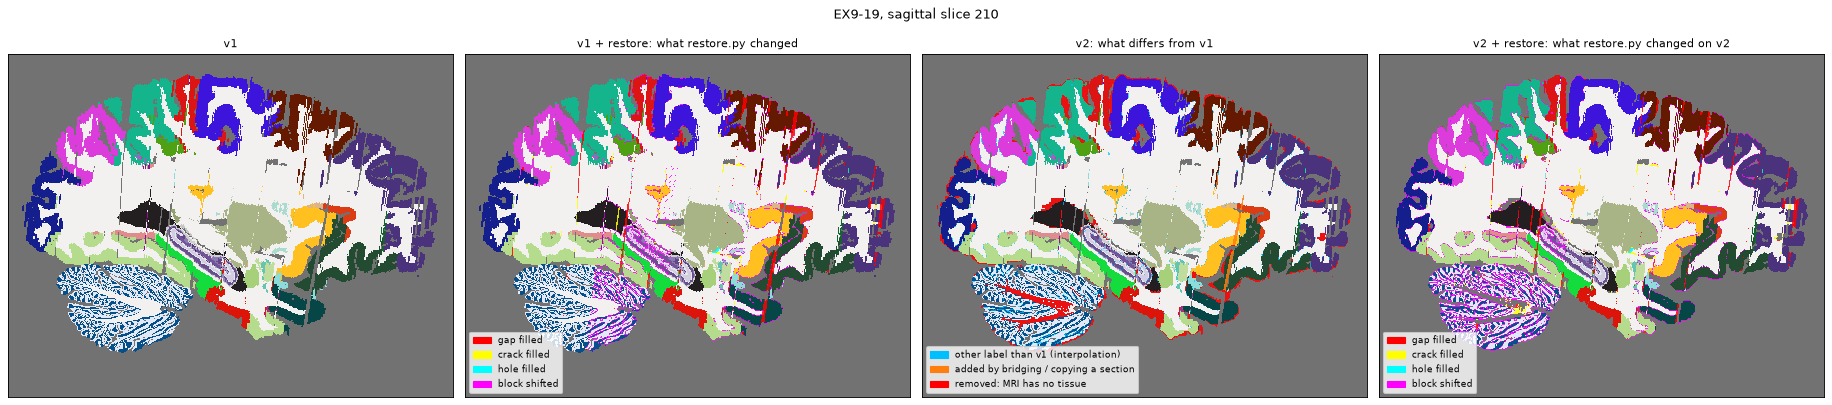

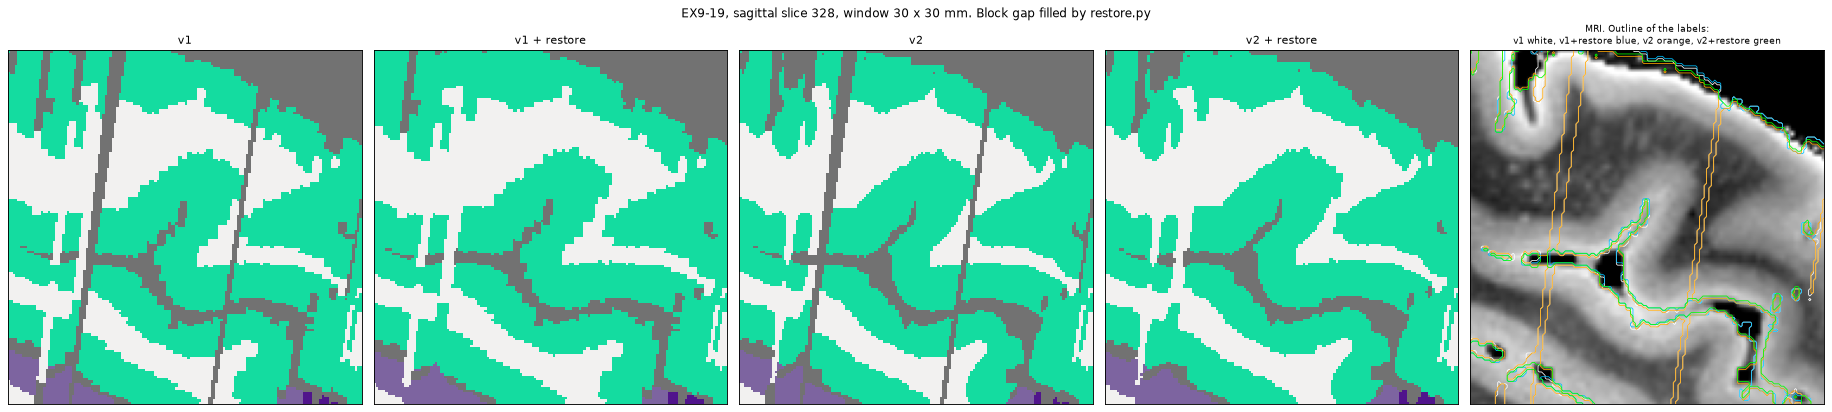

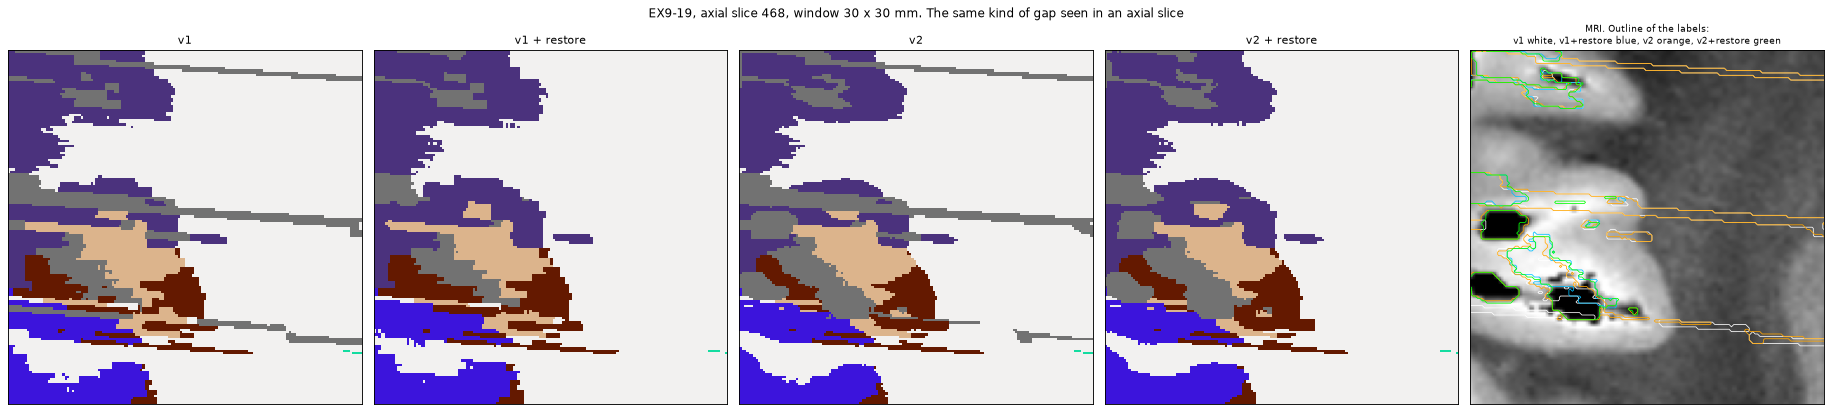

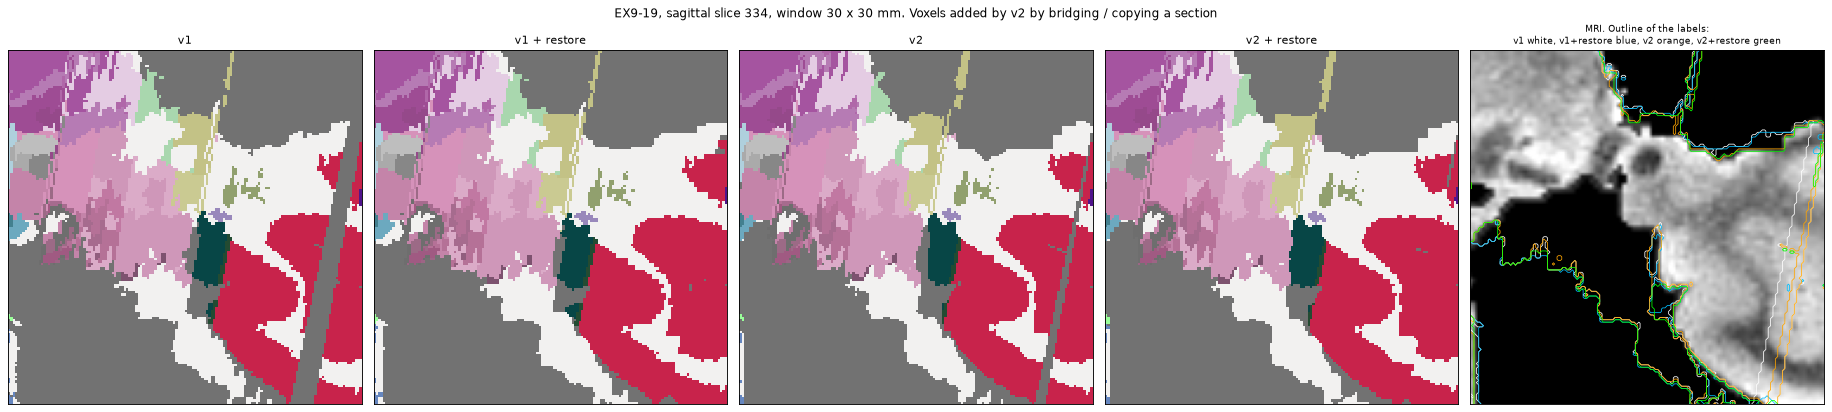

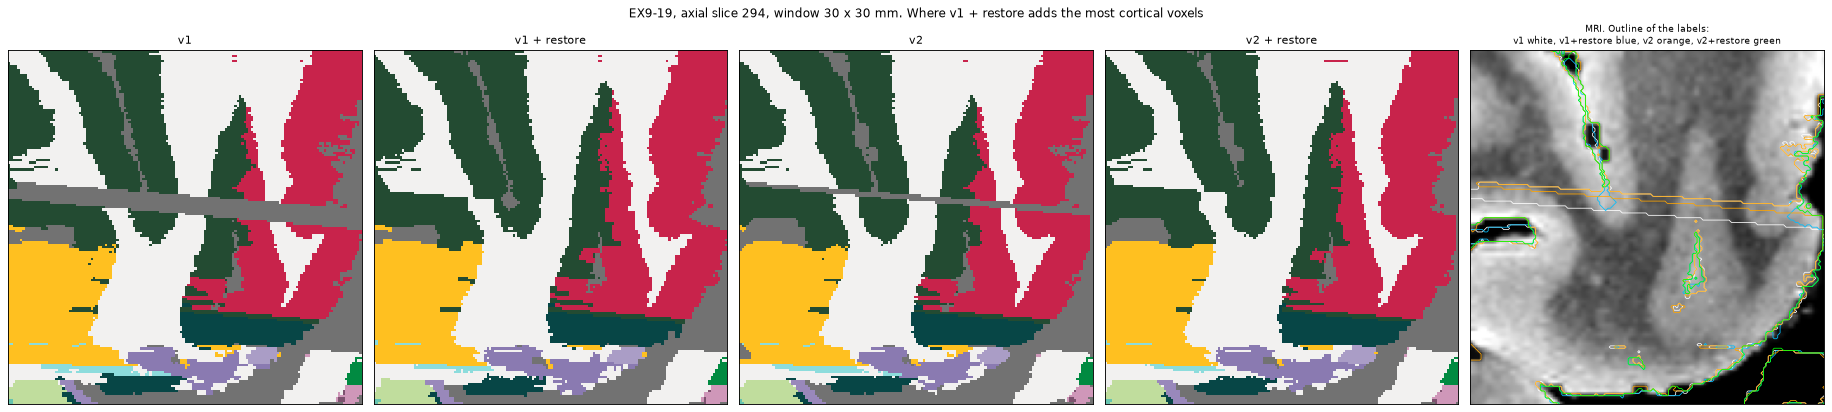

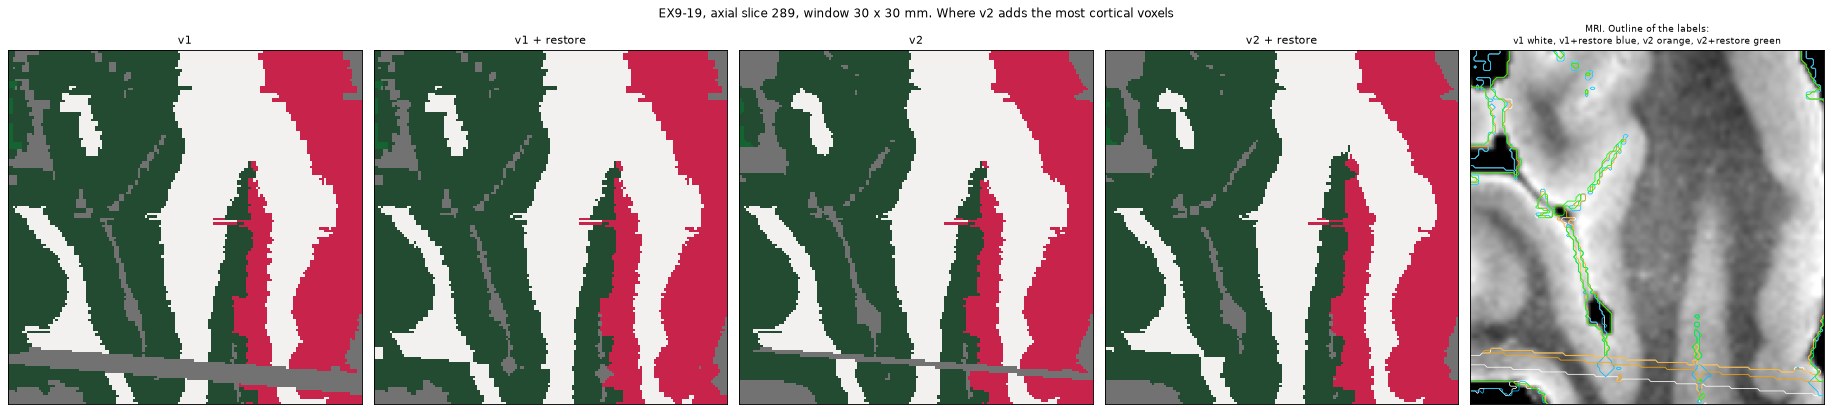

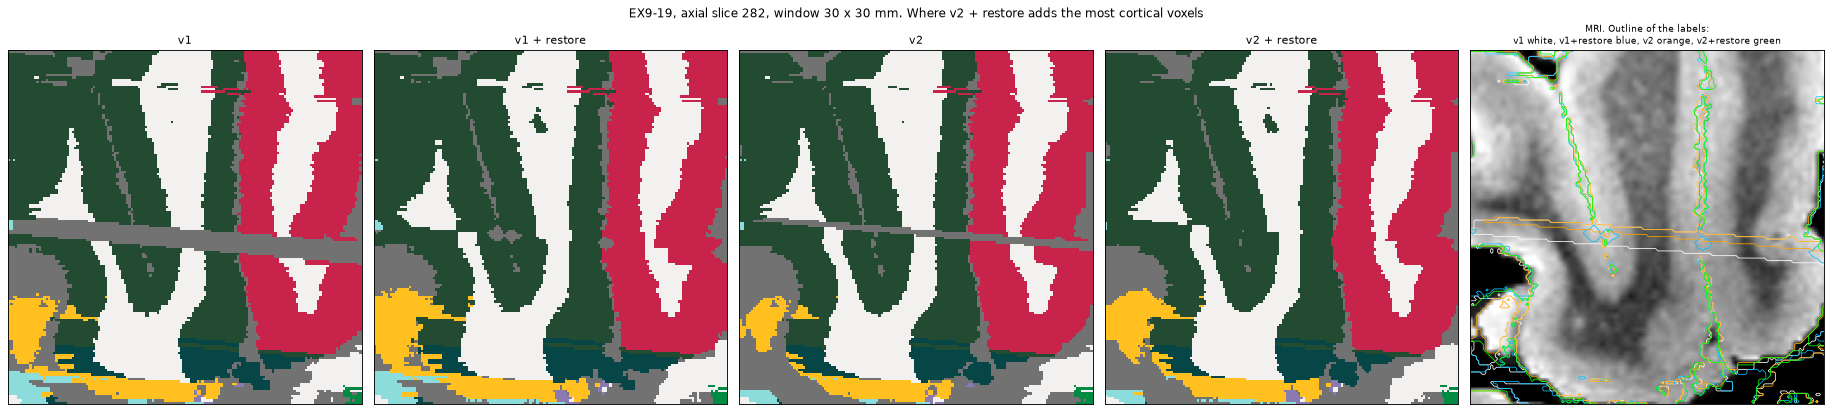

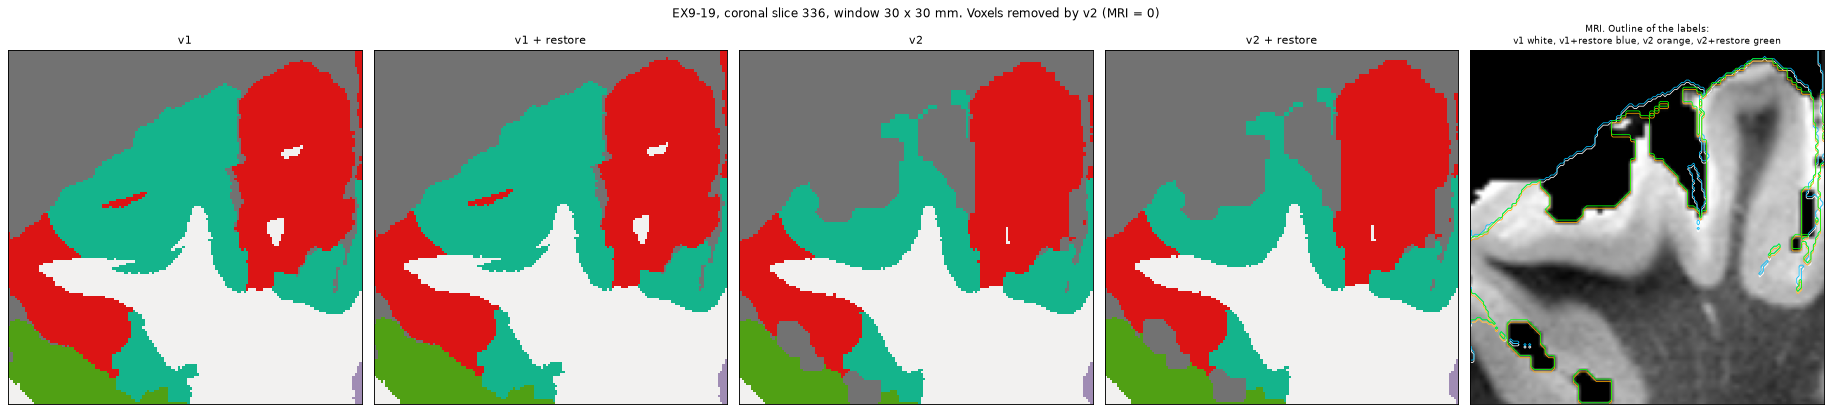

In [10]:
for case in CASES[1:]:
    del C
    C = Case(case)
    change_maps(C, 0, save=f"{C.case}_changes_sagittal.png")
    i, win = pick(C, C.vol["restore_steps"] == 1, 0)
    zoom(C, 0, i, win, "Block gap filled by restore.py", save=f"{C.case}_zoom_gap.png")
    i, win = pick(C, C.vol["restore_steps"] == 1, 2)
    zoom(C, 2, i, win, "The same kind of gap seen in an axial slice", save=f"{C.case}_zoom_gap_axial.png")
    bridged = (C.vol["v2_steps"] == 2) & (C.vol["v1"] == 0) & (C.vol["v2"] > 0)
    i, win = pick(C, bridged, 0)
    zoom(C, 0, i, win, "Voxels added by v2 by bridging / copying a section", save=f"{C.case}_zoom_bridged.png")
    for m in METHODS[1:]:
        add_cx = (C.vol[m] > 0) & (C.vol["v1"] == 0) & IS_CORTEX[C.vol[m]]
        i, win = pick(C, add_cx, 2)
        zoom(C, 2, i, win, f"Where {NAME[m]} adds the most cortical voxels", save=f"{C.case}_zoom_cortex_{m}_axial.png")
    i, win = pick(C, C.vol["v2_steps"] == 4, 1)
    zoom(C, 1, i, win, "Voxels removed by v2 (MRI = 0)", save=f"{C.case}_zoom_trim.png")

## 5. Between two sections: one hidden section

The held-out test of the quantitative notebook, on one example. A section of a block is hidden and
predicted from its two neighbours: by copying one of them (what `v1` does half-way) and by
shape-based interpolation (what `v2` and `v2 + restore` do: `restore.py` does not act between sections). Red = pixels with a wrong label.

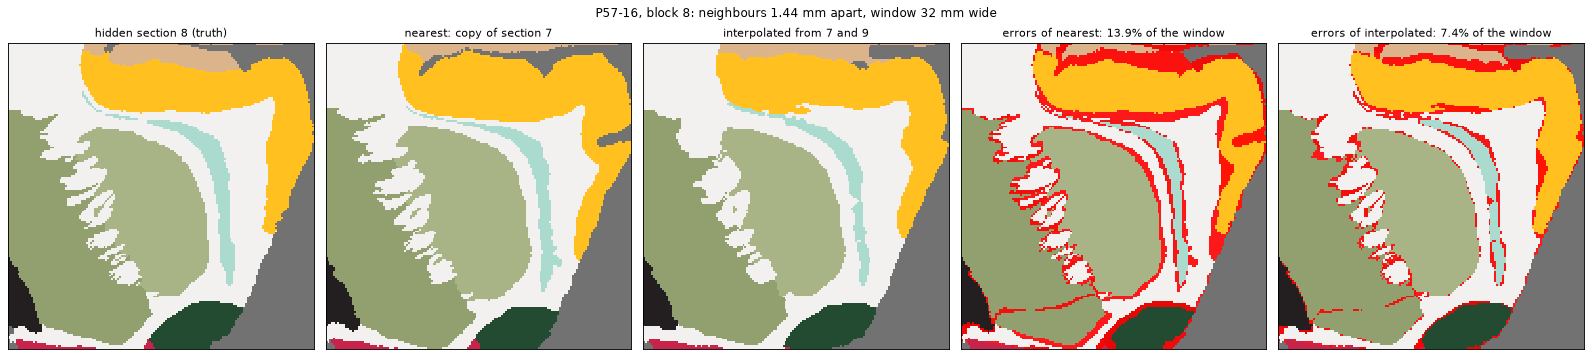

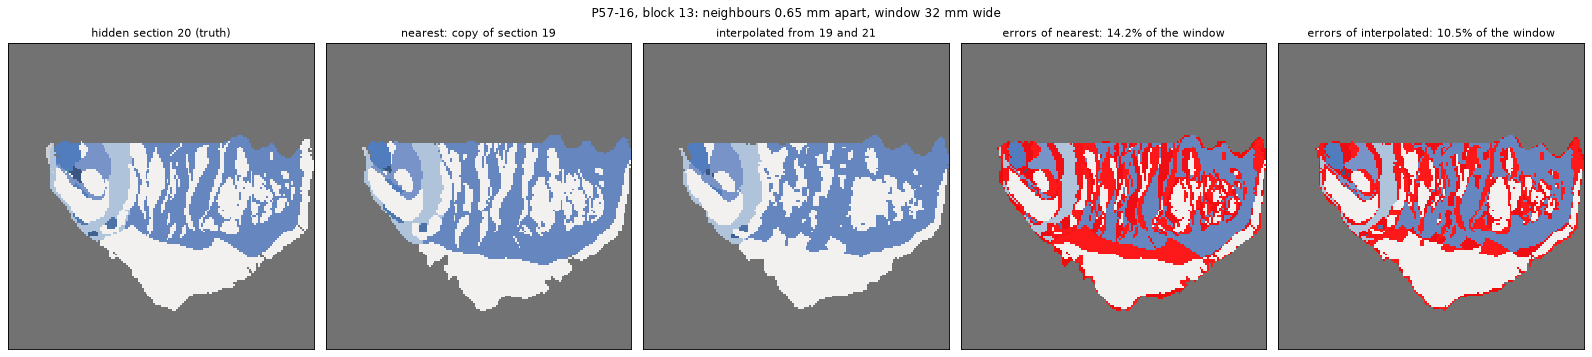

In [11]:
import build_3d_segmentation_v2 as V2
from heldout_sections import interpolate

def hidden_section(case, block, k, win=None, save=None):
    img = nib.load(os.path.join(CASE_DIRS[case], "labels_blocks", str(block), "LABELS.nii.gz"))
    lab = np.asanyarray(img.dataobj).astype(np.uint16)[::2, ::2, :]
    pix = float(np.linalg.norm(img.affine[:3, 0])) * 2; dz = float(np.linalg.norm(img.affine[:3, 2]))
    truth, a, b = lab[:, :, k], lab[:, :, k - 1], lab[:, :, k + 1]
    pred = interpolate(V2.section_sdt(a, pix, 1.0), V2.section_sdt(b, pix, 1.0), truth.shape, np.float32(pix))
    if win is None:
        win = best_window((a != truth) | (pred != truth), 160)
    fig, axs = plt.subplots(1, 5, figsize=(20, 4.6))
    show_lab(axs[0], truth[win], win, f"hidden section {k} (truth)")
    show_lab(axs[1], a[win], win, f"nearest: copy of section {k - 1}")
    show_lab(axs[2], pred[win], win, f"interpolated from {k - 1} and {k + 1}")
    for ax, p, n in ((axs[3], a, "nearest"), (axs[4], pred, "interpolated")):
        show_lab(ax, truth[win], win, f"errors of {n}: {100 * (p != truth)[win].mean():.1f}% of the window")
        overlay(ax, (p != truth)[win], "red", win, 0.9)
    plt.suptitle(f"{case}, block {block}: neighbours {2 * dz:.2f} mm apart, window {(win[0].stop - win[0].start) * pix:.0f} mm wide", fontsize=11)
    plt.tight_layout()
    if save: fig.savefig(os.path.join(FIG, save), dpi=110)
    plt.show()

hidden_section(CASES[0], 8, 8, save="heldout_example_block8.png")       # sections every 0.72 mm
hidden_section(CASES[0], 13, 20, save="heldout_example_block13.png")    # brainstem block, sections every 0.33 mm

## 6. What the images show

| where to look | v1 + restore (option 1) | v2 (option 2) | v2 + restore (option 3) |
|---|---|---|---|
| **Block gaps in the cerebrum** (3.1, section 4) | Closed, in the five cases. The tissue on both sides is joined with the nearest label. | Narrower but **still open** in most places: in EX9-19 the gap stripes are almost unchanged. | Closed, as in option 1. |
| **Staircase** (3.1, section 5) | Unchanged: the steps of v1 are still there on both sides of the filled gap. | Gone: borders are smooth and slanted. In the hidden-section example of block 8 the wrong pixels drop from 13.9% to 7.4% of the window. | Gone, as in option 2. It is the only result with both closed gaps and smooth borders. |
| **Cerebellum and brainstem** (3.2) | The layer missing at the end of the cerebellar blocks is **not** filled: `restore.py` only looks for gaps along the AP axis. | Filled by copying the last usable section, and the result follows the MRI. | Filled (inherited from v2). |
| **Small structures at the end of a block** (3.6) | Small growth where a gap was filled with the nearest label. | The copy of the last section can create a **blocky patch** of a small label (rostral medullary velum: 6.6 → 12.0 mm³ in P57-16). | Inherits the patches of v2, plus the growth of restore. |
| **Labels outside the MRI** (3.4, section 4) | Kept. | Removed. In EX9-19 a whole patch of cortex labelled in histology lies where the MRI is black and is deleted: right if the tissue is really absent from that hemisphere, wrong if the MRI mask is too tight. This cannot be decided from the labels. | Removed (inherited from v2). |
| **Sulci** (3.3) | In the windows with the most added cortex, the additions are gap fillings across the cortex; no sulcus is obviously closed there. This was checked by eye on a few windows only. | Same remark. In P57-16 the largest additions of v2 are in the cerebellum (bridged sections). | Adds the most cortex of the three (the additions of v2 and of restore together), so it is the one to check most carefully. |
| **Block shifts** (section 2) | The magenta voxels: a block moved by one voxel changes all its borders (whole cerebellum in P57-16). The visual gain is not obvious. | Not applicable. | Blocks are shifted too, but **not the same ones**: on v2, `restore.py` shifts no block in P58-16 (3 on v1), fewer in P85-18, and one block of P57-16 by 4 voxels (1 on v1). The shift estimate depends on the input, so it should not be trusted much in either option (`--no-shifts` switches it off). |
| **Cracks and holes** (3.5) | Mostly left: the ones bounded by cortex cannot be told apart from sulci. | Same. | Same. |

In one sentence: **`restore.py` repairs what is missing between blocks, `v2` repairs what is wrong
between sections, and `v2 + restore` does both** at the price of the side effects of both
(trimming and blocky patches from v2, block shifts from restore).